<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/QP-day1/QP_Day1_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> <a href="https://kaggle.com/kernels/welcome?src=https://github.com/imguru-mooc/AI_CAMPUS/blob/main/QP-day1/QP_Day1_lecture.ipynb" target="_blank"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle"/></a>

# Quantization·Pruning Day 1 — 양자화의 수학: 숫자를 INT8 에 담기

**온디바이스 AI · Quantization·Pruning 1/6 · 11/16(월)** · Google Colab 또는 Kaggle (하드웨어 없음) · NumPy · PyTorch

ONNX·TensorRT 과목에서는 모델을 **FP32 · FP16** 으로 배포했습니다. 이번 과목은 숫자 하나에 쓰는 byte 를 더 줄이고(**양자화**), 필요 없는 weight 를 없애서(**가지치기**) 모델을 더 작고 빠르게 만듭니다.

오늘은 라이브러리 없이 **NumPy 만으로** 양자화를 직접 계산합니다. 내일부터 쓰는 ONNX Runtime · TensorRT 의 양자화 옵션은 모두 오늘 만드는 함수 몇 개의 조합입니다.

> **범위 정하기** → **scale · zero-point 계산** → **quantize** (실수 → 정수) → **dequantize** (정수 → 실수) → **오차 재기**

오늘의 목표

1. 경량화가 필요한 이유를 **크기 · 메모리 · 속도 · 전력**으로 설명하고, 모델 크기를 직접 계산할 수 있다.
2. FP32 · FP16 · INT8 · UINT8 의 **표현 범위와 간격** 차이를 말할 수 있다.
3. `scale` · `zero_point` 를 계산하고 **quantize · dequantize** 함수를 만들 수 있다.
4. **대칭 / 비대칭**, **per-tensor / per-channel** 을 데이터에 맞게 고르고 오차로 확인할 수 있다.
5. **clipping** 범위를 바꿔 가며 반올림 오차와 잘림 오차의 trade-off 를 실험할 수 있다.
6. INT8 × INT8 → **INT32 누적** 행렬곱으로 FP32 결과를 재현할 수 있다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | 왜 경량화인가 — 크기 · 메모리 · 속도 · 전력 |
| 2 | 10:00–10:50 | 숫자 표현 — FP32 · FP16 · INT8 · UINT8 |
| 3 | 11:00–11:50 | Affine 양자화 — scale · zero-point · quantize · dequantize |
| 4 | 13:00–13:50 | 대칭 vs 비대칭 — ReLU 출력과 weight |
| 5 | 14:00–14:50 | Granularity — per-tensor vs per-channel |
| 6 | 15:00–15:50 | Clipping 과 Outlier — 범위를 어디까지 잡을까 |
| 7 | 16:00–16:50 | 정수 연산 추론 — INT8 × INT8 → INT32 |
| 8 | 17:00–17:50 | 미니 프로젝트 — 손으로 만드는 INT8 SimpleConvNet · 채점 |

**노트북 사용법**

1. 아래 **0. 실행 환경 준비**대로 Colab 또는 Kaggle 에서 내 사본을 만들어 작업합니다. 오늘은 **CPU** 로 모두 실행됩니다 (GPU 불필요).
2. **✍️ 직접 구현** 셀은 문제를 보고 `# TODO` 부분을 직접 코드로 작성합니다. 실행 후 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다. 막히면 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다.
3. **🔒 정답 보기** 셀은 잠겨 있습니다. 강사가 실습 시간이 지난 뒤 교시별 **잠금 코드**를 알려 주면, 셀을 실행하고 코드를 입력해 정답을 봅니다. 정답을 연 기록은 8교시 채점 셀 결과에 함께 표시됩니다 — 먼저 힌트로 끝까지 시도해 보세요. 🖼 그림 셀은 실행하지 않아도 그림이 보입니다.
4. 매 교시는 **보기 → 따라하기 → 바꿔보기** 순서입니다. `🔁 바꿔보기` 셀은 숫자 하나만 바꿔 결과가 어떻게 달라지는지 관찰합니다.
5. 8교시 미니 프로젝트는 이 노트북 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.
6. 수업이 끝나면 **Day 1 복습 퀴즈**(HTML)를 풀고 제출합니다 — 노트북 맨 끝에 링크가 있습니다.

## 0. 실행 환경 준비 — Colab 또는 Kaggle

이 노트북은 **Google Colab** 과 **Kaggle** 어디서나 똑같이 실행됩니다. 강사가 정한 쪽을 쓰세요.

| 단계 | Google Colab | Kaggle |
|---|---|---|
| 열기 | 맨 위 **Open in Colab** 배지 | 맨 위 **Open in Kaggle** 배지 (또는 *File → Import Notebook* 에서 GitHub 주소 붙여넣기) |
| 내 사본 | *파일 → Drive에 사본 저장* | 열면 내 계정의 노트북으로 만들어짐 · 작업 후 **Save Version** |
| 인터넷 | 기본으로 켜져 있음 | 오른쪽 패널 *Session options* → **Internet On** (처음 한 번 **전화번호 인증** 필요) |
| 가속기 | 오늘은 CPU 그대로 (런타임 유형 변경 불필요) | 오늘은 **None** (Day 3 부터 **GPU T4 x2** 선택 — P100 은 INT8 Tensor Core 가 없음) |
| 생성형 AI | 이 노트북은 **생성형 AI 기능이 숨겨진 상태**로 배포됩니다 (*수정 → 노트북 설정 → 생성형 AI 기능 숨기기* ✅). **다시 켜지 마세요** — 제출 파일에서 이 설정을 확인합니다. *도구 → 설정 → AI 지원* 의 **AI 기반 인라인 완성 표시** 도 꺼 두세요 | 노트북 안에 AI 자동 완성 없음 |
| 숨김 셀 | 🔒 · 🖼 · 💡 셀은 코드가 접혀 있음 | 코드가 보이지만 그대로 실행하면 됨 (정답은 잠금 코드 없이는 보이지 않음) |

> 아래 **환경 셀**을 실행하면 `실행 환경: Colab / Kaggle`, 인터넷 연결 여부가 출력됩니다. `인터넷: 끊김` 이면 위 표의 인터넷 단계를 먼저 하세요.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html) |
| 📝 Day 1 복습 퀴즈 (수업이 끝난 뒤, 24문항) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/review_quiz.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/review_quiz.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/QP_Day1.pdf](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/QP_Day1.pdf) |

**오늘의 데이터 · 모델** — VB Day 1 · OT Day 1 의 **SimpleConvNet** (MNIST, 학습된 가중치 `mnist_cnn.pt`), MNIST 샘플 100장 (`mnist_sample.npz`). 모두 노트북이 자동으로 내려받습니다.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요 (설치할 것 없음: Colab · Kaggle 기본 패키지만 사용)
import os, sys, copy, urllib.request, warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# ── 실행 환경 감지 (Colab · Kaggle · 내 PC) ──
try:
    import google.colab  # noqa: F401
    PLATFORM = "Colab"
except ImportError:
    PLATFORM = "Kaggle" if ("KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.isdir("/kaggle/working")) else "Local"
if PLATFORM == "Kaggle":
    os.chdir("/kaggle/working")                     # Kaggle 에서 쓰기 가능한 폴더

def _online(url="https://raw.githubusercontent.com", timeout=5):
    try:
        urllib.request.urlopen(url, timeout=timeout); return True
    except Exception:
        return False

ONLINE = _online()
print(f"실행 환경: {PLATFORM} | 작업 폴더: {os.getcwd()} | 인터넷: {'연결됨' if ONLINE else '끊김'} | GPU: {torch.cuda.is_available()}")
if not ONLINE:
    print("⚠️ 인터넷이 꺼져 있어 데이터를 내려받을 수 없습니다.")
    if PLATFORM == "Kaggle":
        print("   Kaggle: 오른쪽 패널 Session options → Internet 을 켜세요 (계정 전화번호 인증 필요). 켜면 세션이 다시 시작되니 이 셀부터 다시 실행합니다.")
    else:
        print("   네트워크를 확인하거나, 강사에게 받은 data 폴더를 작업 폴더에 올리세요.")

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
torch.manual_seed(0); np.random.seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/QP-day1"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1"

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버(GitHub Pages → GitHub 원본 순)에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                if os.path.exists(path): os.remove(path)
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 인터넷 연결을 확인하거나(Kaggle: Internet 켜기), 강사에게 받은 파일을 data 폴더에 올린 뒤 다시 실행하세요.")
    return path

import hashlib, base64, datetime
_HINT_N = {}
def show_hint(no, blob):
    # 💡 실행할 때마다 힌트를 하나씩 더 보여 준다
    hints = base64.b64decode(blob).decode("utf-8").split("\x1e")
    k = min(_HINT_N.get(no, 0) + 1, len(hints)); _HINT_N[no] = k
    for i in range(k):
        print(f"💡 힌트 {i + 1}/{len(hints)} — {hints[i]}")
    print("(다시 실행하면 다음 힌트)" if k < len(hints) else "(힌트를 모두 봤습니다 — 이제 직접 구현해 보세요)")
_CODE = {}
def show_answer(no, blob):
    # 🔒 잠금된 정답 보기 — 강사가 알려 준 교시별 잠금 코드가 있어야 열린다
    p = no.split("-")[0]
    raw = base64.b64decode(blob); tag, body = raw[:8], raw[8:]
    for _ in range(2):
        code = _CODE.get(p) or input(f"🔒 {p}교시 잠금 코드: ").strip().upper()
        ks, i = b"", 0
        while len(ks) < len(body):
            ks += hashlib.sha256(f"{code}|qp-day1|{no}|{i}".encode()).digest(); i += 1
        plain = bytes(a ^ b for a, b in zip(body, ks))
        if hashlib.sha256(plain).digest()[:8] == tag:
            _CODE[p] = code
            with open(".qp_answer_log", "a") as f:
                f.write(f"{no}\t{datetime.datetime.now():%H:%M}\n")
            print(plain.decode("utf-8")); return
        _CODE.pop(p, None)
        if not code: break
    print("❌ 잠금 코드가 맞지 않습니다. 강사가 코드를 공개하면 다시 실행하세요.")

def mse(a, b):
    """평균 제곱 오차 — 양자화 오차를 하나의 숫자로"""
    return float(np.mean((np.asarray(a, np.float64) - np.asarray(b, np.float64)) ** 2))

print("NumPy", np.__version__, "| PyTorch", torch.__version__)

## 1교시 — 왜 경량화인가: 크기 · 메모리 · 속도 · 전력

### 이번 과목의 6일 — 하루에 한 계단

| 일차 | 날짜 | 계단 | 만드는 것 |
|---|---|---|---|
| **Day 1** | 11/16(월) | **양자화의 수학** | NumPy 로 quantize · dequantize, 손으로 만드는 INT8 CNN |
| Day 2 | 11/17(화) | ONNX Runtime PTQ | `mnv3s_int8.onnx`, calibration 비교, `qp_baseline.csv` |
| Day 3 | 11/18(수) | PTQ 디버깅 · TensorRT INT8 | layer 별 오차 분석, YOLOv8n INT8 엔진 · mAP |
| Day 4 | 11/19(목) | QAT | fake quantization · STE, PTQ vs QAT 비교 |
| Day 5 | 11/20(금) | Pruning | unstructured vs structured, fine-tuning |
| Day 6 | 11/23(월) | 통합 경량화 | Pruning + 증류 + INT8 → 침입 감지 파이프라인 |

> 🎬 **애니메이션** [D1-1 모델 다이어트](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html#d1-1)
> 애니메이션으로 **예측**하고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

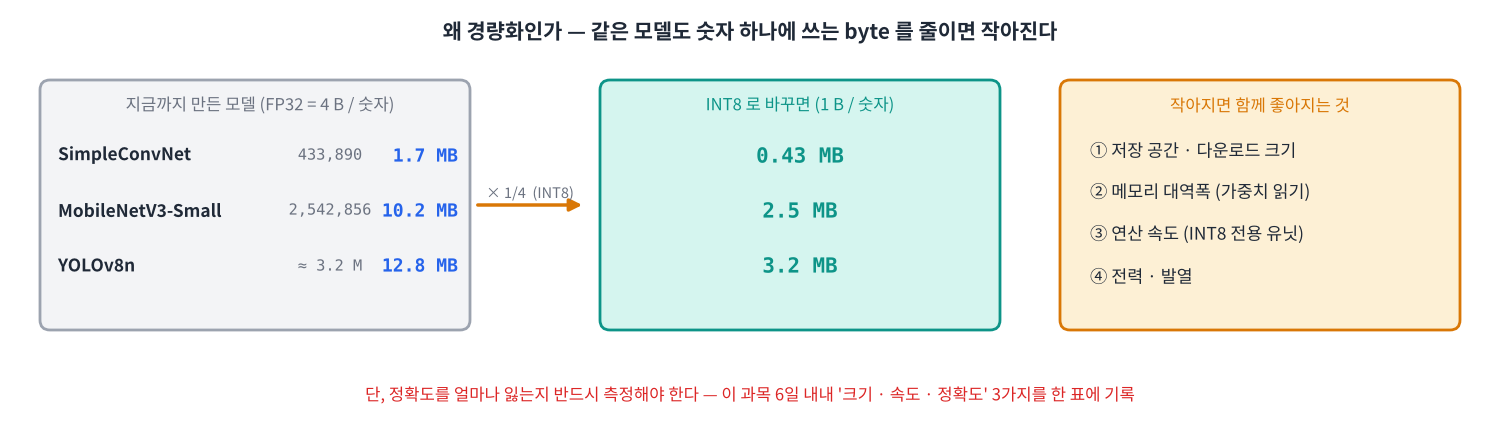

In [ ]:
#@title 🖼 그림 — 작아지면 함께 좋아지는 것 — 저장 · 메모리 · 속도 · 전력
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f1_why.png", embed=True, width=860))

현장 카메라 옆 장치(Jetson · Raspberry Pi · MCU)는 Colab 보다 **메모리가 작고, 메모리에서 숫자를 읽어 오는 속도(대역폭)도 느립니다.** 추론 한 번마다 모든 가중치를 메모리에서 읽어야 하므로, 숫자 하나가 4 byte → 1 byte 가 되면 읽을 양이 1/4 로 줄어듭니다.

먼저 VB · OT 과정에서 쓴 **SimpleConvNet** 을 다시 불러옵니다. 오늘 하루 종일 이 모델의 **진짜 학습된 가중치**로 실험합니다.

In [ ]:
class SimpleConvNet(nn.Module):                 # VB Day 1 · OT Day 1 과 같은 구조
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 30, 5)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(30 * 12 * 12, 100)
        self.fc2 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv(x)))     # (N, 30, 12, 12)
        x = x.flatten(1)                        # (N, 4320)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

cnn = SimpleConvNet()
cnn.load_state_dict(torch.load(fetch("mnist_cnn.pt"), map_location="cpu"))
cnn.eval()
d = np.load(fetch("mnist_sample.npz"))
digits, labels = d["images"], d["labels"]                 # (100, 28, 28) uint8, (100,)
X = torch.from_numpy(digits.astype(np.float32) / 255)[:, None]   # (100, 1, 28, 28)
with torch.no_grad():
    logits_fp32 = cnn(X).numpy()
pred_fp32 = logits_fp32.argmax(1)
print("FP32 정확도 (100장):", (pred_fp32 == labels).mean())
for name, p in cnn.named_parameters():
    print(f"{name:12s} {str(tuple(p.shape)):16s} {p.dtype}")

**✍️ 직접 구현 1-1** SimpleConvNet 의 파라미터 수 `n_params` 와, FP32 (숫자 하나 4 byte) 로 저장할 때의 크기 `fp32_mb` (MB = 10⁶ byte) 를 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-1 — 실행할 때마다 하나씩
show_hint("1-1", "66qo64247J2YIOuqqOuToCDtjIzrnbzrr7jthLDripQgYGNubi5wYXJhbWV0ZXJzKClgIOuhnCDtlZjrgpjslKkg6rq864K8IOyImCDsnojsirXri4jri6QuHu2FkOyEnCDtlZjrgpjsnZgg7JuQ7IaMIOqwnOyImOuKlCBgLm51bWVsKClgIOKAlCDrqqjrkZAg642U7ZWY66m0IO2MjOudvOuvuO2EsCDsiJjsnoXri4jri6QuHkZQMzIg64qUIOyIq+yekCDtlZjrgpjsl5AgNCBieXRlLCBNQiDripQgMTDigbYgYnl0ZSDroZwg6rOE7IKw7ZWp64uI64ukLg==")

In [ ]:
# ✍️ 직접 구현 1-1 — n_params (정수) 와 fp32_mb (실수) 를 만드세요
n_params = None   # TODO: 파라미터 수
fp32_mb = None    # TODO: FP32 크기 (MB)

print(f"파라미터 {n_params:,} 개 → FP32 {fp32_mb:.3f} MB")

In [ ]:
assert n_params == 433_890 and abs(fp32_mb - 1.73556) < 1e-6; print("✅", f"{fp32_mb:.3f} MB")

In [ ]:
#@title 🔒 정답 보기 1-1 — 강사가 알려 준 1교시 잠금 코드를 입력하세요
show_answer("1-1", (
    "F3h8B8+l4ua8SR9FirqBHlIXOu2BY9P5VF7p0RPP6fQeRreuqjD0nFPA20dwEx0WlVnYXUgrd4tBeITDICkU4l6q"
    "bUeqFW+t/Fq5o5VW+6IKsMMf1kUYnj0UgDvjm74itJE5y9tZBMCOmCaGx8vo4HBoxrsD+XtxnnO9k/uqaiwePlnA"
    "lafGY1kDGdqAFm2IeuJaCCtOSae1OtPrs7AWl9vrm9ZHoWfGwX+CWD8rPBjTBW8CUTw3/UuxhmR1IP1M2jvdEzOY"
    "x06NGE5NJ/8EEXQPJUHa96P0em4vmMEPQ1izYZxtOhA0ssWX+wqrohUtJ/KmFWYVuO+ebeJSePviPlHQDDWGIf4g"
    "KmrQ7BYvsyT2YkmxykWwZngCpdIhpm1tndB/rqL6XATAV0kWMCMauEUosSKDB8Z5jGkorWFRejQIbaEE/dhZjg/B"
    "RtHiXatuk2EpVHZ0/f5vnyliSg8HfozfkhsnWdoS"
))


**✍️ 직접 구현 1-2** 세 모델을 FP32 · FP16 · INT8 로 저장할 때의 크기(MB) 표를 만드세요. 자료형별 byte 수를 `BYTES` 에 채우고, 크기 = 파라미터 수 × byte 수입니다.

- MobileNetV3-Small 은 `torchvision` 으로 구조만 만들어 셉니다 (가중치 내려받기 없음).
- YOLOv8n 은 OT Day 5 의 `yolov8n.onnx` 안 가중치 개수(initializer 원소 수)를 미리 세어 둔 값입니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-2 — 실행할 때마다 하나씩
show_hint("1-2", "7J6Q66OM7ZiV67OEIGJ5dGUg7IiY66W8IOyCrOyghCBgQllURVNgIOyXkCDrhKPsirXri4jri6Qg4oCUIEZQMzIgNCwgRlAxNiA/LCBJTlQ4ID8uHmBzaXplX21iW+uqqOuNuF1b7J6Q66OM7ZiVXSA9IO2MjOudvOuvuO2EsCDsiJggw5cgYnl0ZSAvIDFlNmAg7J24IDLri6gg7IKs7KCE7J2EIOunjOuTreuLiOuLpC4e7IKs7KCEIOyViOyXkCDsgqzsoITsnYQg66eM65Oc64qUIGRpY3QgY29tcHJlaGVuc2lvbjogYHttOiB7ZHQ6IC4uLiBmb3IgZHQgaW4gQllURVN9IGZvciBtIGluIFBBUkFNU31g")

In [ ]:
# ✍️ 직접 구현 1-2 — BYTES 사전과 size_mb[모델][자료형] (MB) 을 만드세요
import torchvision
PARAMS = {
    "SimpleConvNet": n_params,
    "MobileNetV3-Small": sum(p.numel() for p in torchvision.models.mobilenet_v3_small(weights=None).parameters()),
    "YOLOv8n": 3_193_934,                  # OT Day 5 yolov8n.onnx initializer 원소 수
}
BYTES = None      # TODO: {"FP32": 4, "FP16": ..., "INT8": ...}
size_mb = None    # TODO: {모델: {자료형: MB}}

print(f"{'모델':20s}{'파라미터':>12s}" + "".join(f"{dt:>10s}" for dt in BYTES))
for m in PARAMS:
    print(f"{m:20s}{PARAMS[m]:>12,}" + "".join(f"{size_mb[m][dt]:>8.2f}MB" for dt in BYTES))

In [ ]:
assert BYTES == {"FP32": 4, "FP16": 2, "INT8": 1} and PARAMS["MobileNetV3-Small"] == 2_542_856
assert abs(size_mb["MobileNetV3-Small"]["INT8"] - 2.542856) < 1e-9; print("✅ INT8 = FP32 의 1/4")

In [ ]:
#@title 🔒 정답 보기 1-2 — 강사가 알려 준 1교시 잠금 코드를 입력하세요
show_answer("1-2", (
    "JLmAc6kz8QljD8sAQtfMFhANNtl7f+UiTarjLKcNFiEPkwqp4wmi0PazaU75pqfkVSoFvATQy01Uyn0CeRmK8T6W"
    "D5j3coScYSZ6dW+ipAzSxlGIO9g+83P+p1Gc2g+JK6DbSZPCDdqst9niw7jb8WJj431nXvNsVSgexdUbIoP0XR7O"
    "49HRetUMefP5k0hx2lzHX0KMqAhNmsVtTdMaLD2PyTiXP0QZycfN6oh8dnB9k0HbhpATzotYpDzjOG6iL4nNs5qH"
    "bMquAaO1aL43HvVDATxXURXZ2CSD5TNdCk0ASCHCNMMfcdJQ2aKofq8V2hNSE/Y93n8M6F6XvsRE2Oq9s8QlISqq"
    "VF+rT3TyxZ02t6fFuE+glVwuU+Lj+5i7ubPpszjTCuq285PDOnHoCqzmpULZoSNYBZrt/Fuf/e4kqdOXt7HeGB9y"
    "OF+hBgROy/lfMFGZjfuOrvZRz1YFgSEyG4WI52EyalkLRfo8bKF/4Eps+E3ofptfoxI2PytkvBSJ1uoA1QDzIEzE"
    "qOgLWCe6DRPRfvmeEZ6TTeM1Upnnexbe4s+smDdwftE2aqjm2kQaU1OBLWXSIPti3YXzfcvmxYZ0OaxKrwWiNcZq"
    "kllmR281OGg+Vll94rlqWHyV0tk+vZ1BwOvqXIT1vTkeirOWK7YMbrFNh2gmxt5k9PoDknSouqpn9yrW4XL5jqjy"
    "dgox//aXvCqkG5xo2pY+GM9zGVarmdMqNdpDF4dLvVXaprtaRCicjPj5B8ZKzYnb/2syYzMtRzB2pFHHXYngqBAa"
    "iWno+mTxYFcepWwBSzR2RaRAL3ksye/qYPWe4Y/6+gLsGvfPirmn43wEhyfLGsrWBIb7DENQ8Tb5PhoVyPVVC3Nr"
    "RseiEhXHo9CYj4XaYNY7wbviLIcVw4OicEjTCRsgN7PfmWG5tSjwEXEhCNx81U6erH5QY6kNQ06xjV7mUr2YyqxB"
    "C+MbfiZCrcXfJeP8wJp8tzn/NTngA4Nif0srCsIeMteXGM8Z80TXaPqB8T6+lzppNRKijKN5Tu40oj07NK4XnAlq"
    "dI5IHrwAEr1srYoWVHpN1AGwXVAwNJ2Iv2LgtB2+66bzNxGzhfV7xeNIBV6y"
))


**✍️ 직접 구현 1-3** SimpleConvNet 을 INT8 로 바꾸면 FP32 보다 몇 배 작아지나요? `ratio` 에 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 1-3 — 실행할 때마다 하나씩
show_hint("1-3", "66y47KCcIDEtMiDsnZggYHNpemVfbWJgIOyXkOyEnCBTaW1wbGVDb252TmV0IOydmCBGUDMyIOqwkuqzvCBJTlQ4IOqwkuydhCDqurzrg4Xri4jri6QuHuuqhyDrsLAg7J6R7JWE7KGM64qU7KeAID0g7YGwIOqwkiDDtyDsnpHsnYAg6rCSLg==")

In [ ]:
# ✍️ 직접 구현 1-3 — ratio = FP32 크기 / INT8 크기
ratio = None      # TODO

print(f"{ratio:.1f} 배 작아진다")

In [ ]:
assert ratio == 4.0; print("✅", ratio, "배")

In [ ]:
#@title 🔒 정답 보기 1-3 — 강사가 알려 준 1교시 잠금 코드를 입력하세요
show_answer("1-3", (
    "/n8h3s1u+Hx1U8KtxOPv8PzcbkR9Sx3S9RHrEQdMfUNHIyr+t9iQZlXQTBrY4VbMbjiQbPw1iwv5CsmBK4lMxV58"
    "53ll25AoDoxLHM15zwBDmSYFen84IIot+h2qoIHPx+FLfZ70qWXIaX6l0jVXijAmVwFmnmSVgzQVU/W3JkIuyb+x"
    "k1OaMUUzyM8Ql6PC1jny30hGWL/fuBH0q8Z9LRfcfBgFV0zSuOkYxbhIfyb1aqSDTItPlNFJHxR8rOAKG3TifxT0"
    "J3RuDlxwhbt1HaveomQhNCHPOWmCSquaMtkLzaidDqbuhS8P50Mna/sEymkvXQDT3aHfP1sQjWMUywegGXOKNARS"
    "9d/TgHx+s8BOgYua/cw2zRZEdMeim3ua8QyA7HXXrupogEwXRPRo7x4IYzr60wXepLp/rE2uj6Jk9j4M6Xv4PGN1"
    "5iOu4XFdcHfpFbEj"
))


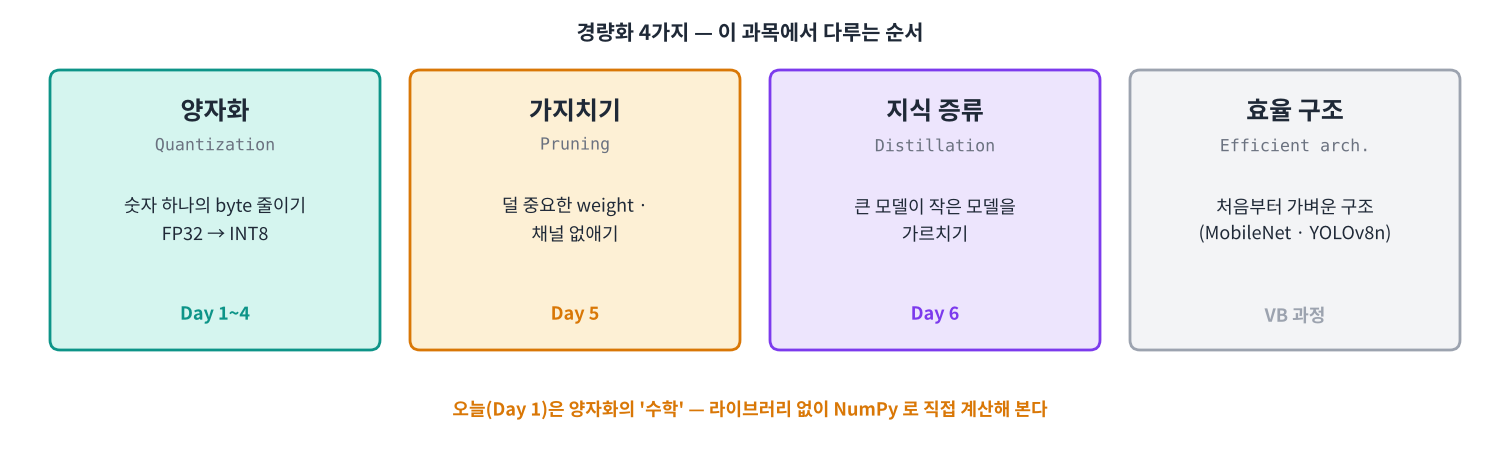

In [ ]:
#@title 🖼 그림 — 경량화 4가지 — 양자화 · 가지치기 · 지식 증류 · 효율 구조
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f1_four.png", embed=True, width=860))

### 🔁 바꿔보기 — 4비트, 2비트로 줄이면?

INT4 는 숫자 하나에 0.5 byte 입니다. `BITS` 를 바꿔 SimpleConvNet 크기가 어떻게 되는지 보세요. 비트를 줄일수록 작아지지만, **담을 수 있는 서로 다른 값의 개수(2^BITS)** 도 줄어듭니다.

In [ ]:
BITS = 4                                       # 16, 8, 4, 2 로 바꿔 보세요
print(f"{BITS} 비트 → 서로 다른 값 {2**BITS} 개 · 크기 {n_params * BITS / 8 / 1e6:.3f} MB")

#### ⚠️ 자주 하는 오해

- "크기가 1/4 이면 속도도 4배" → 아닙니다. 속도는 **하드웨어 · 런타임이 INT8 연산을 지원하는지**에 달렸습니다 (Day 2 · 3 에서 측정).
- "INT8 이면 정확도도 1/4 로 떨어진다" → 아닙니다. 잘 하면 정확도 손실은 1%p 안팎입니다. **얼마나 잃는지 측정하는 것**이 이 과목의 핵심입니다.

#### 📌 1교시 정리

- 모델 크기 = 파라미터 수 × 숫자 하나의 byte. FP32 4 · FP16 2 · INT8 1.
- 경량화 4가지: 양자화 · 가지치기 · 지식 증류 · 효율 구조. 이 과목은 앞의 셋을 다룬다.
- 경량화 결과는 항상 **크기 · 속도 · 정확도** 세 가지를 함께 기록한다.

## 2교시 — 숫자 표현: FP32 · FP16 · INT8 · UINT8

양자화를 하려면 먼저 각 자료형이 **어떤 범위의 숫자를, 어떤 간격으로** 담는지 알아야 합니다.

> 🎬 **애니메이션** [D1-2 비트로 숫자 담기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html#d1-2)
> 애니메이션으로 **예측**하고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

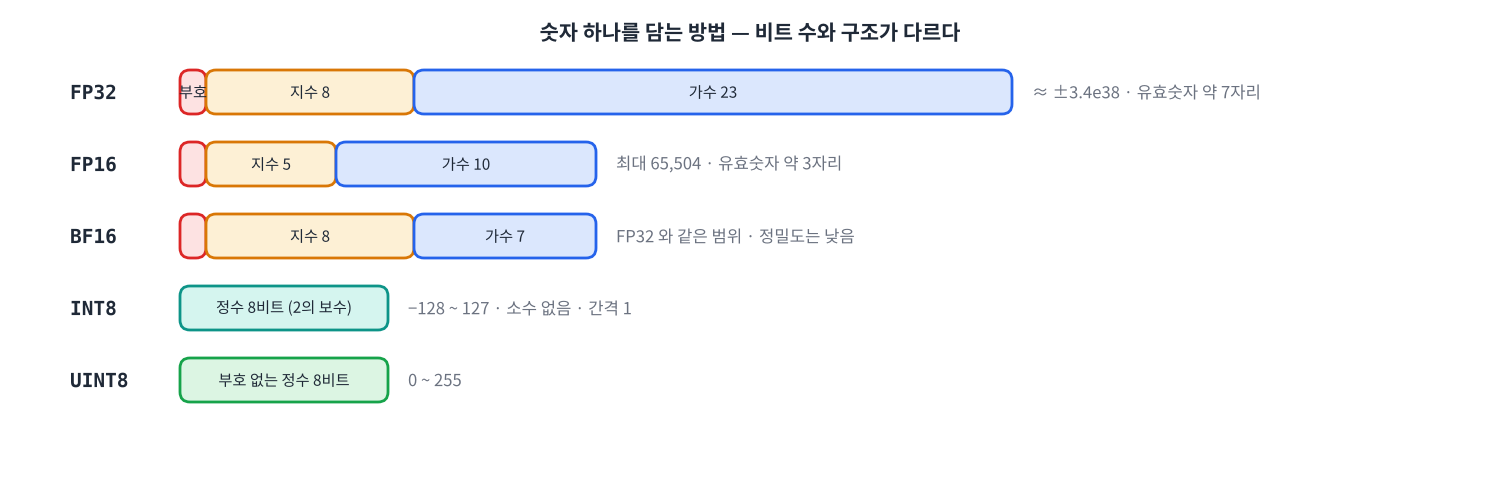

In [ ]:
#@title 🖼 그림 — FP32 · FP16 · BF16 · INT8 · UINT8 의 비트 구조
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f2_bits.png", embed=True, width=860))

### 보기 — NumPy 로 자료형 정보 꺼내기

부동소수점은 `np.finfo`, 정수는 `np.iinfo` 로 범위를 봅니다.

In [ ]:
for t in [np.float32, np.float16]:
    fi = np.finfo(t)
    print(f"{t.__name__:8s} 최대 {fi.max:.4g}  가장 작은 정상 양수 {fi.tiny:.3g}  1 다음 숫자와의 간격(eps) {fi.eps:.3g}")
for t in [np.int8, np.uint8, np.int32]:
    ii = np.iinfo(t)
    print(f"{t.__name__:8s} {ii.min:>12,} ~ {ii.max:,}")

**✍️ 직접 구현 2-1** INT8 과 UINT8 의 범위를 `np.iinfo` 로 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 2-1 — 실행할 때마다 하나씩
show_hint("2-1", "7KCV7IiYIOyekOujjO2YleydmCDrspTsnITripQgYG5wLmlpbmZvKOyekOujjO2YlSlgIOydtCDslYzroKQg7KSN64uI64ukLh5gLm1pbmAgwrcgYC5tYXhgIOyGjeyEseydhCDsnb3sirXri4jri6Qu")

In [ ]:
# ✍️ 직접 구현 2-1 — INT8 범위 (lo, hi) 와 UINT8 범위 (ulo, uhi)
lo, hi = None, None      # TODO
ulo, uhi = None, None    # TODO

print("INT8 :", lo, "~", hi, "| UINT8:", ulo, "~", uhi, "| 서로 다른 값", hi - lo + 1, "개")

In [ ]:
assert (lo, hi, ulo, uhi) == (-128, 127, 0, 255); print("✅ 둘 다 256 개의 값")

In [ ]:
#@title 🔒 정답 보기 2-1 — 강사가 알려 준 2교시 잠금 코드를 입력하세요
show_answer("2-1", (
    "JCcP29ftd/YmRfxCj5s3KjEAhzZ+TV45vBz3f1CDwmFSt4YS4IQ4SNRTDt5XhcWY3H+Tihm5Fm1fQxsKOsgepdQe"
    "noi9YXLcbLZVrqdjd9WVmL7nR06QbIkJl3ANfrFOodNCIQnm8RJJmMxM7aIliBOpm/5XRwXRPHf2pkP3WxJ/uzEg"
    "7LtZGi+cglN3Bt+9V56HIytBLo4x/31GfDX2TIox329PDeu2uyvMEa2mkcL1o+N/pLB726t+xI8Ip2R2e+LOgEdG"
    "xlbcgbgQ6rOYRoVvMtM36camtd3Ax1iNj9OycRX8Sobmsn3x6f43zw/3cfOYIXr/s/daSeQStLqE+FFDFfg36p7/"
    "1eD2obYFH3Vwiz5jiwAU2fFGYMFb9rq09kD6/y+lqrmp0sTbv3u3UmJ5B7JdG+/Q2yooIY1JemlsQ+vr0c62Hda1"
    "hZ1e1j4zDE+qJW/RTYC5ZDChmFwxcl5y/W5PVdspJPP7adpSNRWJk+3V9dkdlc4P9nvn0uN5b4HLRC80bD0XXtvQ"
    "2TH7T6hqJj62rEY6lRRu7PzmHj+O65oxbq/+olcOqA3KIbbXNrfpWRyV15ve8Ie7Bitj/tln0Lb7GArCIHWE+rGf"
    "tK9vqamjDzbI2dnV0GEOow+1gBtGx8+t0nv9nQ1Wj4ovsV83kA=="
))


**✍️ 직접 구현 2-2** FP32 값을 FP16 으로 바꾸면 무엇이 달라질까요? `x` 를 FP16 으로 바꿔 `x16` 에 넣고, FP16 이 담을 수 있는 최댓값 `fp16_max` 를 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 2-2 — 실행할 때마다 하나씩
show_hint("2-2", "7J6Q66OM7ZiVIOuzgO2ZmOydgCBg67Cw7Je0LmFzdHlwZShucC7snpDro4ztmJUpYCDsnoXri4jri6QuHuywqOydtOulvCDsnrQg65WM64qUIEZQMTYg6rCS7J2EIOuLpOyLnCBgbnAuZmxvYXQzMmAg66GcIOuwlOq+vCDrkqQg67m87JW8IOygle2Zle2VqeuLiOuLpC4e67aA64+Z7IaM7IiY7KCQIOyekOujjO2YleydmCDsoJXrs7TripQgYG5wLmZpbmZvKOyekOujjO2YlSlgIOKAlCDstZzrjJPqsJLsnYAgYC5tYXhgLg==")

In [ ]:
# ✍️ 직접 구현 2-2 — x16 (FP16 배열), err (FP32 와의 차이), fp16_max (float)
x = np.array([0.1, 1.0, 1000.1, 70000.0], np.float32)
x16 = None        # TODO
err = None        # TODO
fp16_max = None   # TODO

for a, b, e in zip(x, x16, err):
    print(f"FP32 {a:>10} → FP16 {b:>10}   차이 {e}")
print("FP16 최댓값:", fp16_max)

In [ ]:
assert x16.dtype == np.float16 and np.isinf(x16[3]) and fp16_max == 65504.0
print("✅ 70000 은 FP16 범위를 넘어 inf")

In [ ]:
#@title 🔒 정답 보기 2-2 — 강사가 알려 준 2교시 잠금 코드를 입력하세요
show_answer("2-2", (
    "mtW3nS3ZWFDgsGLkPG1WmcQQ8YcUYxPhzKICndSSpWu2UM+UeNxnuW3CHsklR+bpvq/zEWEE9GHvkD+8ps2nGQ7f"
    "8E5+z5lDjQDoCSjgQFwu39ZcVeu1XMwh5UBdNgXWxqwoJv23G6qpFSisc5mwk+P7DypnUcSR6yRaVxZ4TXLDNlJg"
    "xpq1iRvoFGu0jzVnsxoZvpFEHXeTgRH0DgMIAfRRvcPuN3PjMaLj1h/R57BT3nHt2RH+rKmZOMGPQ4KfL4Ak29Ma"
    "cFZFHqoWxJfv29RwdVTqcd0HlFGaHRA3/CQc+4am/DIkG16zmJiE00nxsfxJQqOIUkZ8FuSmGWqY3Gznz6qtvrNZ"
    "9TS7IypkfXz1LJ3JbztM5jnTrSj9Y3xHIxdC3xBEqGScszBCyONzNLXlBa+t0UEfMCxD7zSzivGTNkxh4aobgN5D"
    "Yj8DCcIZQ+TVz1L3IVbO0jBe45OyYgaiYSb7BnTbWlYlf/5Lx6s4IIdRYzvF9ApH7FFz38FcLHBtXxQ6+Qe5EMaC"
    "yKivkADAmU5NG76mwtswuCbmx10IhsjOi0uSYTrr4fENpd8zq1wwGy6HvwAZGSmw4rZ32VIHvYW3HPRKHOvI4gwQ"
    "mpYizWpn6YuB3XxUdmkL8kJ8uKrarQOWmO1xWOkS8DwoQTnakKVPDqoWSFo1zHiBYntZgSqYaOl8A4WerXWjewGU"
    "iSJvQhDRgOPwnGHblQgrgp9iGUwqdHaMbHTfSORv4X7GAskS7yTjkhvMSy55T22gxb/ZnDycRramMaLHQq9wXKv5"
    "gqJdlZhsvo862y2oLMPsGcnFlkdWnFQjQi8dbotzhBV5KWYG+4fEOery4qzSUm0Tz9kJE+er"
))


### 실수를 그냥 INT8 로 바꾸면?

`astype(np.int8)` 은 **소수점을 버리고**, 범위를 넘으면 **한 바퀴 돌아(wrap-around)** 엉뚱한 값이 됩니다. 아래 결과에서 200 이 −56 이 되는 것을 확인하세요.

In [ ]:
v = np.array([0.3, 1.7, -1.6, 200.0, -300.0])
print("astype(np.int8) 만 :", v.astype(np.int8))

**✍️ 직접 구현 2-3** 올바르게 바꾸려면 **반올림 → 범위 자르기(clip) → 형 변환** 순서여야 합니다. `safe` 를 완성하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 2-3 — 실행할 때마다 하나씩
show_hint("2-3", "7Iic7ISc6rCAIOykkeyalO2VqeuLiOuLpDog6rCA7J6lIOqwgOq5jOyatCDsoJXsiJjroZwg4oaSIOuylOychCDslYjsnLzroZwg4oaSIO2YlSDrs4DtmZguHu2VqOyImDogYG5wLnJvdW5kYCwgYG5wLmNsaXAo67Cw7Je0LCDstZzshowsIOy1nOuMgClgLCBgLmFzdHlwZShucC5pbnQ4KWAuHklOVDgg67KU7JyE64qUIOusuOygnCAyLTEg7JeQ7IScIOq1rO2VnCDiiJIxMjggfiAxMjcu")

In [ ]:
# ✍️ 직접 구현 2-3 — v 를 올바르게 INT8 로 바꾼 safe 를 만드세요
safe = None       # TODO

print("round → clip → int8:", safe)

In [ ]:
assert safe.tolist() == [0, 2, -2, 127, -128]; print("✅", safe)

In [ ]:
#@title 🔒 정답 보기 2-3 — 강사가 알려 준 2교시 잠금 코드를 입력하세요
show_answer("2-3", (
    "XWMv3+9ETd4z7CZCZ25hJvomzfUhsG8WAFp4c3iUTAQiqwanYdfi8TEKOcgClSHM1wL2WzzjTD2kBTNjirZxh9B2"
    "AY437hvUWCz9m7RFD92Ae4sz8tUH25OAicoJ2j73SHBrCkhnjEuabnn0BkPf4U4/ulnsin1NmgWnmMKly88NHDjP"
    "UrGsiNuay9vKSUC0oEd+A8wwyQ2OXZoJ4dSg701QCQHGbczW/aaIxu63CXH/HnzF4Lgsh3+ynoBqggRlWElrS1Xm"
    "5RavlWnYSY0q29XWi/5i2BoltMdN6GzC/d0GVi9/wIdjwjqGRJVLqhHThoDRBVBRxbiF213uSu6W3laGn/vM4F+f"
    "TX0qIEd7OdNxv88+l2DoveuPUPwKyPzz7zMYu7Xq9PSAs+9dw5oXMPv6ymuNdGSVgzr7xMEsFMvG7xSWe6+0WBuA"
    "QI8wyMgZwIpVX46YYHnnTr5+M2yB8B+TIuNRS21VIgOwiFjw4fvU//DQ2KPh36Ojhgm98cb98Z9ySWOCvEhHhXDQ"
    "rvnSL+03BCb/WOvNJ+W6pf+d5iJ6PzlPz54sixGBChkkryLUVLXSD8xO/wQkk7wyGbza7x6eitAHyxj8wPJeCynp"
    "wguIE9wOsL/i"
))


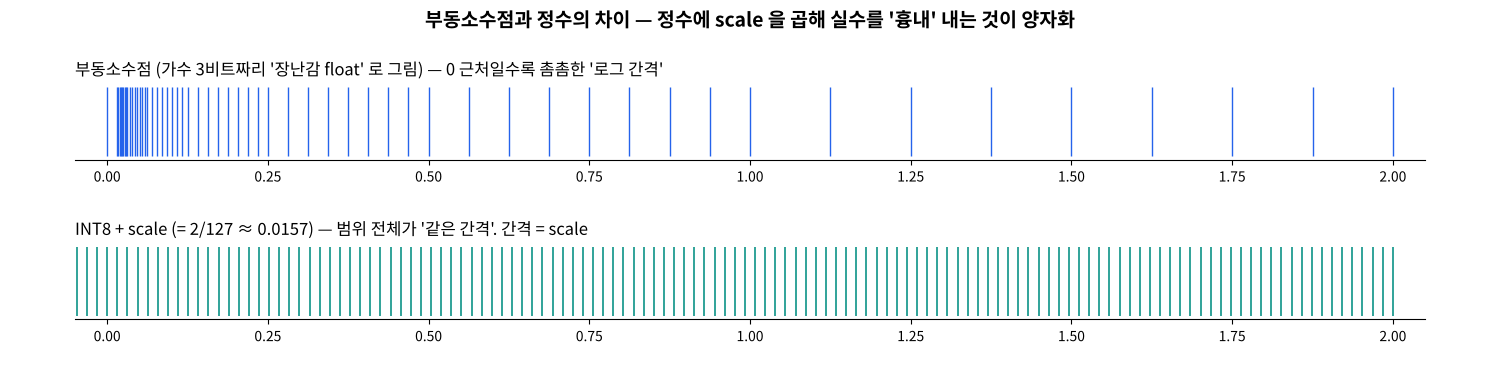

In [ ]:
#@title 🖼 그림 — 부동소수점은 0 근처가 촘촘하고, 정수 + scale 은 간격이 일정하다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f2_grid.png", embed=True, width=860))

### 🔁 바꿔보기 — 정수끼리 곱하면?

INT8 끼리 곱한 결과도 INT8 에 담으면 넘칩니다. `a` · `b` 를 바꿔 보세요. 이 문제는 7교시에 INT32 누적으로 해결합니다.

In [ ]:
a, b = 100, 100                                # 10, 50, 100, 127 로 바꿔 보세요
print(f"INT8 × INT8 = {np.int8(a) * np.int8(b)}   (진짜 답 {a * b})")
print(f"INT32 로 곱하면 = {np.int32(a) * np.int32(b)}")

#### ⚠️ 자주 하는 실수

- `x.astype(np.int8)` 로 바로 변환 → 소수점 버림 + wrap-around. 항상 **round → clip → astype**.
- `np.uint8` 배열끼리 빼기 → 음수가 255 근처 큰 수가 됩니다. 계산 전에 `astype(np.int32)` 로 넓히세요.

#### 📌 2교시 정리

- FP32 · FP16 은 '지수 + 가수' — 범위가 넓고 0 근처가 촘촘하다. FP16 최대 65,504.
- INT8 · UINT8 은 256 칸 · 간격 1. 소수가 없어서 **scale** 이 있어야 실수를 담을 수 있다.
- 정수 변환은 round → clip → astype. 곱셈 · 누적은 더 넓은 정수(INT32)에서.

## 3교시 — Affine 양자화: scale · zero-point · quantize · dequantize

양자화는 **실수 구간 [xmin, xmax] 를 정수 구간 [qmin, qmax] 에 겹쳐 놓는 것**입니다. 필요한 숫자는 두 개뿐입니다.

- **scale** — 정수 1칸이 실수로 얼마인가 (간격)
- **zero_point (zp)** — 실수 0.0 이 정수 몇 번 칸에 놓이는가

$$\text{scale} = \frac{x_{max} - x_{min}}{q_{max} - q_{min}}, \qquad zp = q_{min} - \text{round}\left(\frac{x_{min}}{\text{scale}}\right)$$

$$q = \text{clip}\left(\text{round}\left(\frac{x}{\text{scale}}\right) + zp,\ q_{min},\ q_{max}\right), \qquad \hat{x} = (q - zp) \times \text{scale}$$

> 🎬 **애니메이션** [D1-3 scale · zero-point 조절기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html#d1-3)
> 애니메이션으로 **예측**하고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

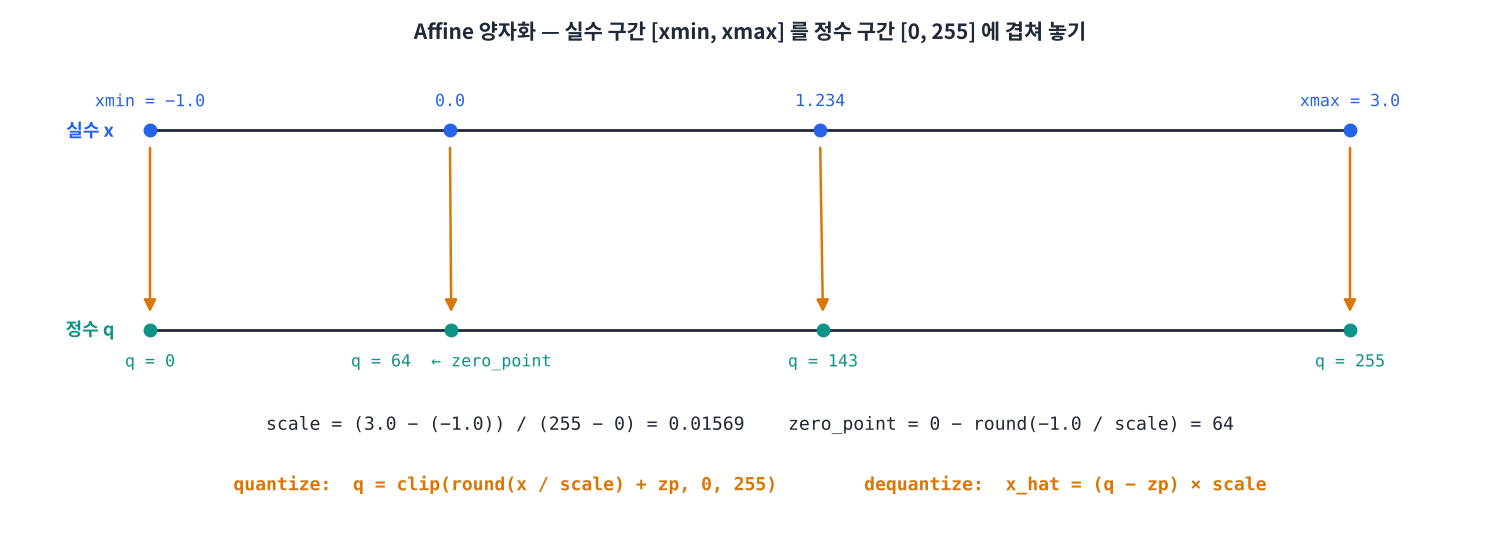

In [ ]:
#@title 🖼 그림 — [−1, 3] 을 UINT8 [0, 255] 에 겹치기 — scale 0.01569, zero_point 64
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f3_affine.png", embed=True, width=860))

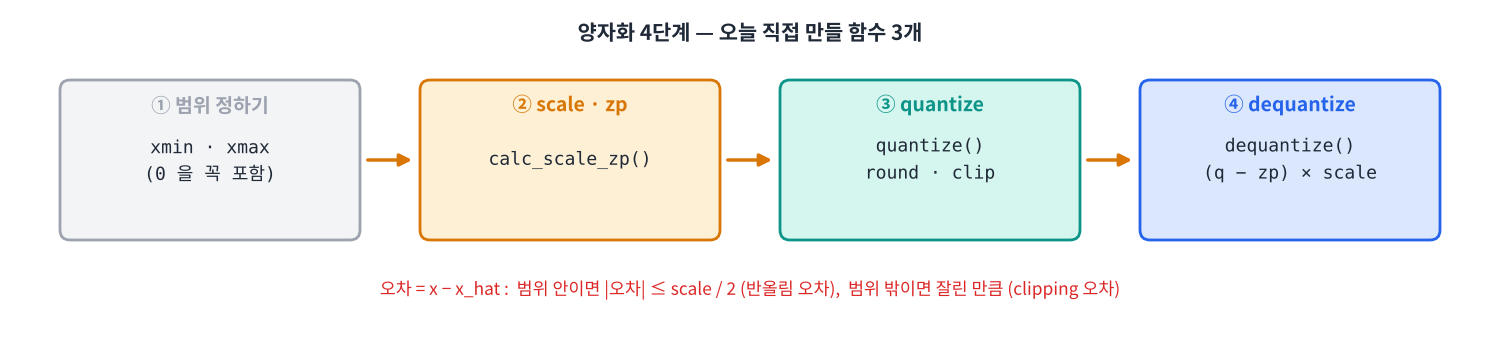

In [ ]:
#@title 🖼 그림 — 양자화 4단계 — 범위 → scale · zp → quantize → dequantize
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f3_steps.png", embed=True, width=860))

**왜 범위에 0 을 꼭 넣을까?** 신경망에는 0 이 아주 많습니다 (ReLU 출력, padding). 0 이 정수 칸에 **정확히** 놓여야 0 이 0 으로 되돌아옵니다. 그래서 `xmin = min(xmin, 0)`, `xmax = max(xmax, 0)` 로 범위를 넓힙니다.

**✍️ 직접 구현 3-1** `calc_scale_zp` 를 완성하세요. 기본값은 UINT8 (qmin 0, qmax 255) 입니다. `[-1, 3]` 이면 scale = 4/255, zp = 64 가 나와야 합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 3-1 — 실행할 때마다 하나씩
show_hint("3-1", "66i87KCAIOuylOychOyXkCAwIOydhCDtj6ztlajsi5ztgrXri4jri6Q6IGB4bWluID0gbWluKHhtaW4sIDApYCwgYHhtYXggPSBtYXgoeG1heCwgMClgLh5zY2FsZSA9ICh4bWF4IOKIkiB4bWluKSAvIChxbWF4IOKIkiBxbWluKS4eenAgPSBxbWluIOKIkiByb3VuZCh4bWluIC8gc2NhbGUpIOulvCBgaW50YCDroZwsIOq3uOumrOqzoCBxbWluIH4gcW1heCDslYjsnLzroZwgY2xpcC4eeG1heCA9PSB4bWluICjrqqjrkZAgMCkg7J2066m0IOuCmOuIl+yFiOydhCDtlLztlbQgYHJldHVybiAxLjAsIHFtaW5gLg==")

In [ ]:
# ✍️ 직접 구현 3-1 — scale 과 zero_point 를 돌려주는 함수
def calc_scale_zp(xmin, xmax, qmin=0, qmax=255):
    # TODO: ① 0 포함  ② 모두 0 이면 (1.0, qmin)  ③ scale  ④ zp (정수, qmin~qmax)
    pass

s, zp = calc_scale_zp(-1.0, 3.0)
print(f"scale = {s:.6f}  zero_point = {zp}")

In [ ]:
assert abs(s - 4 / 255) < 1e-12 and zp == 64
assert calc_scale_zp(0.5, 3.0) == (3.0 / 255, 0); print("✅ scale", round(s, 6), "zp", zp)

In [ ]:
#@title 🔒 정답 보기 3-1 — 강사가 알려 준 3교시 잠금 코드를 입력하세요
show_answer("3-1", (
    "K/XWspNgWsECz98ueA3P2vH1j38rH2q/Olbuq37Gpc1uUIpavpONbabtj7lvOFXF9KFFl01UpIFaYDNhqjhQHUez"
    "QVWRs1vSi9NHvK4MUevE4WsKE9LzaVtP1LlZQIJ9OoPCY5V3fOPVVqVlm30zwwYFVRHUCmS7HeByvZQ62hIK2rjY"
    "QluHQ6RXvWD+K0Pq8ziG3vVDlWQRYk5As3Wr6erCgmIVmmj3iRVw2T0x7+tuV5RVJQbeJhIOh/SbERGYoSxoT6Jj"
    "SPgSSqWU9ej4CjSnHA0ueCbzeCbLR+G1YDaydG1n/lUJYMtzFy/TuTccWBYO0FrQEoORls78up86Pmr8wS6BGuo/"
    "4I0gaQTtiLfoGjVtzQPerqsviDERSbtYlcRzubRTv1SR7rDOAOavi72Ryk2JC8zR8Dh3vIC1LFeveijvq2xsL7hb"
    "2rVtuubgR8GvBLcpZrAUgYbsCiJ5FlogEcUe7bSLiM6wsK7sx3gA9NPXe2Yud7C2BsckPqoSUixepJSaO231OVYP"
    "YKYwkDmKQYPM61eJq6kIR4HUQjJNdOQrQ6qmr8/2LTUHFwE4T7uSIxqxwuE4G3aO8SGdnzQ+fZi7ct+lvZaofw35"
    "Ry8swwyYcIBU55uEmRV0FfGhcdxHtrKceoIXYvFB/1qKG6yXMWZEW+ZfdMi/lybxEsixtMEvcaJ1MwDgBvksi79d"
    "FLzXbeqYpGvr1NniF1Guw/XxcyKUS/Zz4jcPu2szR+A8gCxKeOF+ARMbdKVuV9/7jsHuMH3eVIkEBlOxttAquqi6"
    "Yz6YrmMrKT3KKqeLWC04zS7bwvNif3WzNSSO0UYJlpNsNX3crYN5ZTatOI3c6Zwzyd691VtnyAqxYS4KmRfpq+zP"
    "NSYiRcxv1aHw8vwf8kcWfVIDg7nDYT++uvgPx3sastQynyjTxdYvRQMq2++0yfOZdZ8rzY1Jkg=="
))


**✍️ 직접 구현 3-2** `quantize` 를 완성하세요. 결과는 **INT32 배열**에 담아 돌려줍니다 (계산 중 wrap-around 방지 — 저장할 때만 8비트로).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 3-2 — 실행할 때마다 하나씩
show_hint("3-2", "eCAvIHNjYWxlIOuhnCAn66qHIOy5uCcg7J247KeAIOq1rO2VmOqzoCBgbnAucm91bmRgIOuhnCDrsJjsmKzrprztlanri4jri6QuHnpwIOunjO2BvCDrjZTtlZwg65KkIGBucC5jbGlwKC4uLiwgcW1pbiwgcW1heClgLh7qsrDqs7zripQgYC5hc3R5cGUobnAuaW50MzIpYCDigJQg6rOE7IKwIOykkSB3cmFwLWFyb3VuZCDrpbwg66eJ6riwIOychO2VtCDrhJPsnYAg7KCV7IiY66GcLg==")

In [ ]:
# ✍️ 직접 구현 3-2 — 실수 → 정수
def quantize(x, scale, zp, qmin=0, qmax=255):
    # TODO: round(x / scale) + zp → clip → int32
    pass

xs = np.array([-1.0, 0.0, 0.5, 1.234, 3.0])
q = quantize(xs, s, zp)
print("x :", xs)
print("q :", q)

In [ ]:
assert q.tolist() == [0, 64, 96, 143, 255] and q.dtype == np.int32; print("✅", q.tolist())

In [ ]:
#@title 🔒 정답 보기 3-2 — 강사가 알려 준 3교시 잠금 코드를 입력하세요
show_answer("3-2", (
    "bB3otXbSmdGZFkvOXwWQSsXgnPyb3SUIG0D0qKCKrFB6R1sKp3PKWAkKfoJmPUzqKkci+T5bvySisutHQqow2iuE"
    "aLFCVHarwyvVeUnqVj2wcV2/nKQzqazahIj2zDudYb5UYsBANm76zoC10cViiymeyZMbQmeVP/3sqWAZrXnSiWvk"
    "8niYCN1h2KlMAz97yyO+IGRbvqoA25eFHrqHCn51aMBktXH2erfy7/yrlQBTEBsHnrA0afEtbuWaCgZwJMXictOw"
    "jcUxmNxK2Ee23iE+lBafRTwxSRU9OWJSrSD5sfkF8cLdVcxGyRF36xkNrvgcbPvqz/oi4vcAiJ35oZdMK4L9i8tW"
    "cfN6yXMGwOZyz3nqq1fPyELoNTL4UDsXFJVxK1i/gFdFsGAA9plGiKDOBMqx36XWFFTk+ZNAL/penyvWCTYBAkk7"
    "XUGD/iMOwp9U3OXB5bFZCnu3EwFpzRGNM8rZq3CWocePL2B5tthWQx5+lGXOLPv9WUlMwzPBl/J8hyQU9w+RFXwj"
    "egmlKIvDMn8mHxYUwgLhpUz4FWx5YbSf9Lics/SNGukYiDASCRP5k8bKOCCs2/5+yJ2C7V3uDsV9ENgOSXwSBou3"
    "zWxFNX+VQOpV24LASsAnH6M7XWHVPOQTlQ=="
))


**✍️ 직접 구현 3-3** `dequantize` 를 완성하고, 범위 안 난수 10,000 개로 **최대 오차가 scale / 2 이하**인지 확인하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 3-3 — 실행할 때마다 하나씩
show_hint("3-3", "ZGVxdWFudGl6ZSDripQgcXVhbnRpemUg7J2YIOuwmOuMgDogenAg66W8IOu5vOqzoCBzY2FsZSDsnYQg6rOx7ZWp64uI64ukLh5xIOqwgCDsoJXsiJgg67Cw7Je07J2066+A66GcIOuovOyggCBgbnAuYXNhcnJheShxLCBucC5mbG9hdDY0KWAg66GcIOyLpOyImOuhnCDrsJTqvrjrqbQg7JWI7KCE7ZWp64uI64ukLh7stZzrjIAg7Jik7LCoID0gYG5wLmFicyjrkJjrj4zrprAg6rCSIOKIkiDsm5Drnpgg6rCSKS5tYXgoKWAu")

In [ ]:
# ✍️ 직접 구현 3-3 — 정수 → 실수, 그리고 난수 10,000 개로 최대 오차 확인
def dequantize(q, scale, zp):
    # TODO
    pass

x_rand = np.random.uniform(-1, 3, 10_000)
x_hat = None      # TODO: x_rand 를 quantize → dequantize
max_err = None    # TODO: 최대 절대 오차

print(f"최대 오차 {max_err:.5f}  ≤  scale/2 = {s / 2:.5f} ?  {max_err <= s / 2 + 1e-12}")
print("0.0 →", dequantize(quantize(0.0, s, zp), s, zp))

In [ ]:
assert max_err <= s / 2 + 1e-12 and dequantize(quantize(0.0, s, zp), s, zp) == 0.0; print("✅ 범위 안 오차 ≤ scale/2, 0 은 정확히 0")

In [ ]:
#@title 🔒 정답 보기 3-3 — 강사가 알려 준 3교시 잠금 코드를 입력하세요
show_answer("3-3", (
    "SuRnf7GQMALcXaVyegujLSRNMugPljCh3dQPT0Ulfz3eSSiT5RdyCIyS88NSXpb7Baw12cpYrfuC7STyBtsqiUbW"
    "Jxo3WWIrcwlXUmMe4PY1CvXpq/cEV8PIxFIbKhhWnQ28JriCr9pFtBghcuVv4f0tHLdEMAe1vAkdBFf67zL8vZdS"
    "FepXjWtAuWGST9fdYJBG4smVvPOypP3Wcp9VhUXXRfxR310VOBGxEtw0amIoNQlW93VhWcw6lJ4Nsc9iPvmI5JtV"
    "FgNVyQZb6EDZy2iIE9rP6jEu/EpDBAq0ljnZc3pKV6qtNYKL0Yu5uEE3IcxmJDskjdMHKVl487Ot7Zi9mmMOASay"
    "GZSXKVYqlIt1jntTAv4tCpybwfYVc6OVRmYCHl0bQXvYiMEFGy/PMof9e+wjHh58zRs+iF/KTOYlFTJNNR7mR5pC"
    "9VAsforbjW93KE3nfteZk4SfB119QEjCtva9cna6ke3B65+1ukJ4Mp6d20tzHZH3lRCY5mhahGy2ynNVeOK8iieh"
    "/OUmz2crpkqp9mlpwdsd0gqyzKUlavwEn1cgmtYtanPGdqOhLSQft2KJoEWuBRNIKhJn2vBgGHFtES9e1j9+b6sk"
    "FaBafQjqHuTq+/U4bK0/zxRWuav0jwnw1oR12Z0TMMDPytc1vMYgAJt05jlnIWl+04DbX4tR3O2/YwPXm9IO2qSq"
    "fsrL468RT1bS770y23bU4TMu2kXDlJ4CfU7lAz5GG8lRnwD84BMaq7WLNWglW61ORi10DL33tmRod4jyY8vAfEwj"
    "ypG2OfNjCTgBp79YaLjmyKRlrULNxD1yCFCPhICB3fjcivC9vUXB"
))


### 범위 밖 값은?

범위 [−1, 3] 밖의 값은 clip 때문에 끝 칸(0 또는 255)에 붙습니다. 이것이 **clipping 오차** 입니다.

**✍️ 직접 구현 3-4** 범위 밖 값 `x_out` 을 양자화 → 역양자화한 값과 오차를 구하세요. 오차가 scale/2 보다 훨씬 큰지 확인합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 3-4 — 실행할 때마다 하나씩
show_hint("3-4", "7JWe7JeQ7IScIOunjOuToCBgcXVhbnRpemVgIOKGkiBgZGVxdWFudGl6ZWAg66W8IOq3uOuMgOuhnCB4X291dCDsl5Ag7KCB7Jqp7ZWp64uI64ukLh7smKTssKjripQg7KCI64yT6rCSIGBucC5hYnMoLi4uKWAu")

In [ ]:
# ✍️ 직접 구현 3-4 — 범위 밖 값의 왕복 결과와 오차
x_out = np.array([4.0, 5.0, -2.0])
x_out_hat = None  # TODO
clip_err = None   # TODO

print("되돌린 값:", x_out_hat.round(4), "| 오차:", clip_err.round(4))

In [ ]:
assert np.allclose(x_out_hat, [(255 - 64) * s, (255 - 64) * s, (0 - 64) * s])
assert clip_err.min() > 10 * s; print("✅ 범위 밖 오차는 scale/2 의", int(clip_err.min() / (s / 2)), "배 이상")

In [ ]:
#@title 🔒 정답 보기 3-4 — 강사가 알려 준 3교시 잠금 코드를 입력하세요
show_answer("3-4", (
    "96kDfQI/7isaHSUgYQ2mHUrwEA/ADp64EaEtc87rcDTSZznBBVyp3Ljjy/K8g5iyXjEK6t8duHf8oe1TMFzlQHw/"
    "HQzL6y5Z2jGb1fS2xCRjuDiIYXBbUiwEO6c/7Th1u/2vAbuPZdVhyIs3UR+mrHoGTg+axBxS7OduNy2cxNEQjG/X"
    "lkQlpvKCwrxh6sTszQaCxF+EU/N4uC4UXJ1ZegArwBcvc1rkVkGvyIwnzAIYB/TQzU3s1SLv6Q9jRLTubM75HXOE"
    "H0NXi1c3hKG9TJnEkw7Loc6oZBNQqtSrVERjGmHYO/Hvo4L9oSqT+8GzYzPaX2ufugQL9dB7qnxXGSP5/JQOxIkm"
    "o104wqLEBqOZG3VHGQ2gIPZZTkAH/ULShcbaT04BMkHcvU0PYE8FsBNalGiD5X5H7RyMW0oopa5wPGHcBcp56TNg"
    "O1c3QKIVIsHT6WaXAqQCIKLqOlrQ8dlEMCUXNhfn1fDD5ByWrylqiO1omNM+GXryvCoSc/W8ODyMVUlzPNLBz5ve"
    "3ypeL67r6x5QsSnde2eRgRJNUhvH7XO84NHzYtrP6z20ixb1hW61/AoyuX/JrdwaoAS2OLc4QxxPfIdkc+CybMpc"
    "5oe9G98jh0cHGVexRJppT5GQ4BYX6SdaHaQYN45lFcZYmRpqpHp7nAUr3xVJ7or+V9lULzhqdQghbBuNJPiinXuX"
    "gD8="
))


### 🔁 바꿔보기 — 비트 수를 줄이면?

`BITS` 를 바꿔 보세요. 칸 수가 줄면 scale 이 커지고, 최대 오차(scale/2)도 커집니다.

In [ ]:
BITS = 4                                        # 8, 6, 4, 2 로 바꿔 보세요
qmax_b = 2 ** BITS - 1
s_b, zp_b = calc_scale_zp(-1.0, 3.0, 0, qmax_b)
err_b = np.abs(dequantize(quantize(x_rand, s_b, zp_b, 0, qmax_b), s_b, zp_b) - x_rand).max()
print(f"{BITS} 비트: 칸 {qmax_b + 1} 개 · scale {s_b:.4f} · zp {zp_b} · 최대 오차 {err_b:.4f}")

#### ⚠️ 자주 하는 실수

- `round` 다음에 `zp` 를 더해야 합니다. `round(x / scale + zp)` 와 결과는 같지만, zp 가 정수가 아니면 달라집니다 — zp 는 항상 **정수**.
- `quantize` 결과를 바로 `np.uint8` 로 저장한 뒤 `q - zp` 계산 → uint8 끼리 빼서 wrap-around. 계산은 INT32 로.
- 범위에 0 을 넣지 않음 → 0 이 정확히 표현되지 않아 ReLU · padding 결과에 작은 오차가 계속 쌓입니다.

#### 📌 3교시 정리

- scale = 범위 / 칸 수, zp = 0.0 이 놓이는 정수 칸.
- quantize = clip(round(x / scale) + zp), dequantize = (q − zp) × scale.
- 범위 안 오차 ≤ scale / 2 (반올림), 범위 밖은 잘린 만큼 (clipping).

## 4교시 — 대칭 vs 비대칭: ReLU 출력과 weight

| 방식 | 범위 | zero_point | 정수 범위 (8비트) | 쓰는 곳 (관례) |
|---|---|---|---|---|
| **비대칭 (asymmetric)** | [xmin, xmax] | 데이터에 따라 | UINT8 0 ~ 255 | 활성값 (ONNX Runtime 기본 U8) |
| **대칭 (symmetric)** | [−max\|x\|, +max\|x\|] | **항상 0** | INT8 −127 ~ 127 | weight (TensorRT 는 활성값도 대칭) |

대칭은 zp = 0 이라 계산이 간단합니다 (7교시). 대신 데이터가 한쪽으로 치우치면 칸을 낭비합니다. −128 은 쓰지 않고 −127 ~ 127 만 써서 0 을 중심으로 정확히 대칭으로 둡니다.

> 🎬 **애니메이션** [D1-4 대칭 · 비대칭 비교](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html#d1-4)
> 애니메이션으로 **예측**하고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

**✍️ 직접 구현 4-1** 대칭 양자화 함수 두 개를 완성하세요. `bits=8` 이면 qmax = 127 입니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 4-1 — 실행할 때마다 하나씩
show_hint("4-1", "Yml0cyDruYTtirgg64yA7Lmt7J2YIOy1nOuMgCDsoJXsiJggcW1heCA9IDJeKGJpdHPiiJIxKSDiiJIgMSAoOOu5hO2KuOuptCAxMjcpLh5zY2FsZSA9IG1heHx4fCAvIHFtYXgg4oCUIGBucC5hYnMoeCkubWF4KClgLh7slpHsnpDtmZQ6IHJvdW5kKHggLyBzY2FsZSkg7J2EIOKIknFtYXggfiBxbWF4IOuhnCBjbGlwLCBgaW50MzJgIOuhnC4genAg64qUIOyXhuyKteuLiOuLpC4=")

In [ ]:
# ✍️ 직접 구현 4-1 — 대칭 양자화 함수 두 개
def sym_scale(x, bits=8):
    # TODO: max|x| / qmax  (float 로 돌려주기)
    pass

def sym_quantize(x, scale, bits=8):
    # TODO: round(x / scale) → clip(−qmax, qmax) → int32
    pass

t = np.array([-2.0, -0.5, 0.0, 1.0])
st = sym_scale(t)
print("scale", st, "| q", sym_quantize(t, st), "| 되돌리면", sym_quantize(t, st) * st)

In [ ]:
assert abs(st - 2 / 127) < 1e-12 and sym_quantize(t, st).tolist() == [-127, -32, 0, 64]; print("✅ zp 없이 q × scale")

In [ ]:
#@title 🔒 정답 보기 4-1 — 강사가 알려 준 4교시 잠금 코드를 입력하세요
show_answer("4-1", (
    "dWPei7BeJyDTcv9LtOWH+kYh26A1/8G8+7a+/47MhWYhlTO46icohGXYFRAHmYG0HR0OYp+RfXpeANPxZNGZqmeP"
    "3k9jATa4u+uxL9ifegNhlZPutzseqkSBTXIX7tVlT8Aq3ykuWi7cGybOogprvWbqvBhvClKs+7LpmqPr4o8w6byt"
    "3+IQiOEECuJA82VYo0vXYDo29tyoiH2Khbcbyj8OjKXh80BgOz3UBLJ7Cvf6IaW6nmreXKL9mJmUiX4slnEr2tZH"
    "6Az90YQalx4p7aMmwlNzCfCkhyMgIPrItYIvs40v2Qlp7RB8w236u+x3VoUba/48uJmGO1QNK87e5WXAUDDTBuwb"
    "jOvyZTU2bqM90PRQ8fkdGEL4/ieu5KLEKYGLQQNiLV7Ri/2w2xuPsr4ntSt+wrqQnBh0zwNTkzu3/1UTicvv5cMZ"
    "GemkB9Y7+RFEQ4xWuAbGZUQoAU0EHS/x62M0tLO6QzLXlRQ46pVDyHPcEJy+f2Al4VMKZe9FCaNhYios+dVJf1Nt"
    "6LOFsJ1zFnSm1jKYyPyCG/S/d3Rr/eXmqUhTL4lo0/iWV3jKiGidr2Yxwrj5nDGSm98PoQDsfQMycBEfwMn7U2bI"
    "XDpeHBc919mU9XcxA9XPoIrdAAmgFALIz/sItieljmjpRcmx10aGhnGkijW5X9VfeHkKXtTIWJhecQLdj65tSP9L"
    "QYcUwc6A/QjXipgpXeUX855ThqVwC1P5YG8T89rmh1+1xs7O/nkvHzIyH6XIGrJYh4StFrQZrK4EmU/pNm3/LZZC"
    "fsN1dZDX5PXYLutz1lsi66+JPNOzT1a6cSBU4rGLRlNb80p4lX0L2nhSruuPESfJCw=="
))


### 실제 데이터 1 — ReLU 뒤 활성값

SimpleConvNet 의 `conv → ReLU → MaxPool` 출력을 MNIST 100장에 대해 모읍니다. ReLU 를 지났으므로 **모두 0 이상**입니다.

In [ ]:
with torch.no_grad():
    A = cnn.pool(F.relu(cnn.conv(X))).numpy().ravel()          # (432,000,)
print(f"값 {A.size:,} 개 | 최소 {A.min():.3f} | 최대 {A.max():.3f} | 0 인 비율 {(A == 0).mean():.1%}")

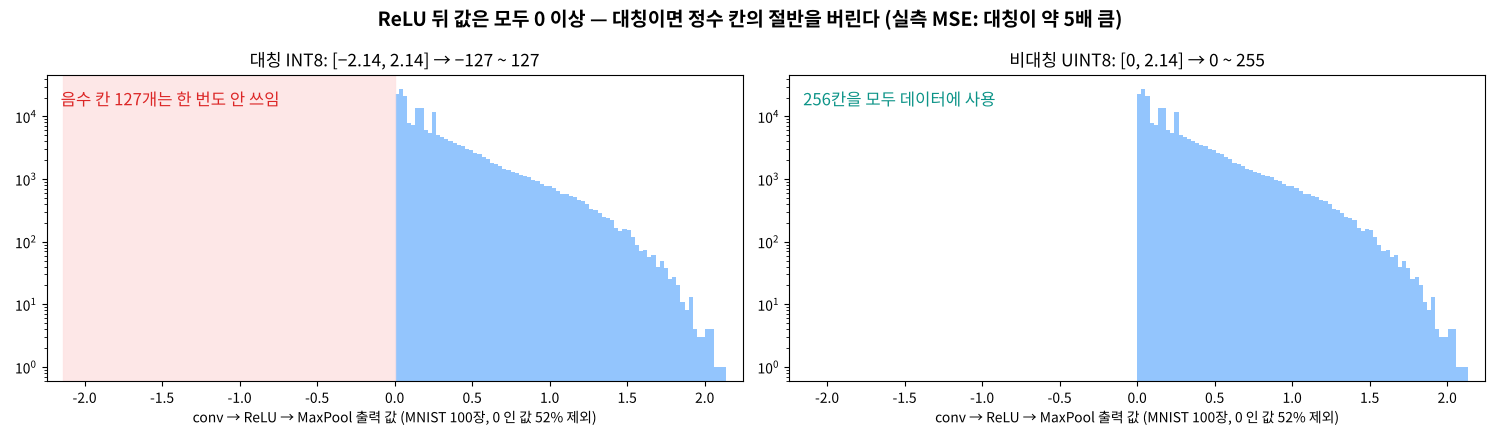

In [ ]:
#@title 🖼 그림 — ReLU 출력에 대칭을 쓰면 음수 칸 절반이 낭비된다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f4_symasym.png", embed=True, width=860))

**✍️ 직접 구현 4-2** 활성값 `A` 를 **비대칭 UINT8** 과 **대칭 INT8** 로 각각 양자화 → 역양자화해 MSE 를 비교하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 4-2 — 실행할 때마다 하나씩
show_hint("4-2", "67mE64yA7LmtOiBgY2FsY19zY2FsZV96cChBLm1pbigpLCBBLm1heCgpKWAg4oaSIHF1YW50aXplIOKGkiBkZXF1YW50aXplIOKGkiBgbXNlKOKApiwgQSlgLh7rjIDsua06IGBzeW1fc2NhbGUoQSlgIOKGkiBgc3ltX3F1YW50aXplYCDihpIg65CY64+M66as6riw64qUIGBxIMOXIHNjYWxlYCDihpIgYG1zZSjigKYsIEEpYC4=")

In [ ]:
# ✍️ 직접 구현 4-2 — 활성값 A 의 비대칭 / 대칭 MSE
s_a, zp_a = None, None   # TODO: 비대칭 UINT8 scale · zp
mse_asym = None          # TODO
s_s = None               # TODO: 대칭 INT8 scale
mse_sym = None           # TODO

print(f"비대칭 scale {s_a:.5f} MSE {mse_asym:.2e}")
print(f"대칭   scale {s_s:.5f} MSE {mse_sym:.2e}  → {mse_sym / mse_asym:.1f} 배")

In [ ]:
assert 4.5 < mse_sym / mse_asym < 5.5; print("✅ ReLU 출력에는 비대칭이 약", round(mse_sym / mse_asym, 1), "배 정확")

In [ ]:
#@title 🔒 정답 보기 4-2 — 강사가 알려 준 4교시 잠금 코드를 입력하세요
show_answer("4-2", (
    "acK3TRZmvEMPLro8uarPrhCx/Zcuocx67wwSTZDEroWBxfPsP6lo7xCiq2S0MEBK4evaaqwDl7piWBJgqMbWx3NN"
    "IZdplOM49H6Fg+vpceD2yoLpwMjVgyrbdXeEbg8/8drcU7z7bCCz+WE2n7xWxJ8afc3qL4V18SCWTApcHc4GxjJL"
    "8K1WvovWMF37d5fjFSjSWyZml/W9SJqjZvtCYbR0wcxNk0erer7LxoF4ATC/Xx9r8opLLEK5K0+mc5CD9Hs+Fro7"
    "aYzFke+uT4lpMlGkto3F2WPoEUmc4g54LMsICYhGNDzIWYhU1s8g/v69VvAijvz/DKfy+NC4bYPzYLSEdI95HCu+"
    "7cGD15mLWC2mDy0m13KL89xgEg8g9auD9X/erkgG1iZ4cuVZtaxZuZkoY2IB3bKgqhH/jGGlPuNLDW07bJzzS31w"
    "O+YeYglUF3WWx/x4bWncaqmSg4GfyD0IbQW5Fq5UgIVt5TEYZYlY4wSUqnLKY5AaShUpLiJEmPLkH/UU0F58CXJr"
    "fdXa2w7JRx15QLH1kZxlnqinL4qNRqOungc/6j32DU6YrBOJ1OddqGXie0jaZ3mFS9P32OVB1zNjbh781IhLzgN6"
    "NiTNaLAd3KJy/BirXO/R+SZcVCCPx9MNmKkEhn8fhi4R9N7VlARyrFtONBxf7vrgM51ejOVT9BLiLwiUGCUK1Gfs"
    "nMKu8YvG09riaXQhqx/ghs8Q3XU55XeqH3DX0y8fSth0eXoySYXUzuCUHYsR28+MGti2TZIqjVSKqjJmWeGdTBCR"
    "uVI0tdyquv5+IbbqFWQov8vGF/TPR6NoP5Fr9NCqEkK2xDs/vdim0NUYiCrxhtkGpNed5jsjvpEqcbE2AEHNl3d9"
    "yPue2Lvt8skrI1wcMXh2F1cTb9l05Lj6oKU="
))


### 실제 데이터 2 — conv weight

weight 는 0 을 중심으로 양쪽에 퍼져 있습니다. 이번에도 대칭이 많이 손해일까요?

**✍️ 직접 구현 4-3** conv weight `W` 에 같은 비교를 하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 4-3 — 실행할 때마다 하나씩
show_hint("4-3", "66y47KCcIDQtMiDsmYAg6rCZ7J2AIOqzhOyCsOydhCBgQWAg64yA7IugIGBXYCDsl5Ag7ZWp64uI64ukLh7rs4DsiJgg7J2066aE66eMIOunnuy2lOuptCDrkKnri4jri6Q6IHdfbXNlX2FzeW0gwrcgd19tc2Vfc3ltLg==")

In [ ]:
# ✍️ 직접 구현 4-3 — conv weight W 의 비대칭 / 대칭 MSE
W = cnn.conv.weight.detach().numpy()                             # (30, 1, 5, 5)
print(f"W 범위 {W.min():.3f} ~ {W.max():.3f}")
w_mse_asym = None        # TODO
w_mse_sym = None         # TODO

print(f"비대칭 MSE {w_mse_asym:.2e} | 대칭 MSE {w_mse_sym:.2e} → {w_mse_sym / w_mse_asym:.2f} 배")

In [ ]:
assert 1.0 < w_mse_sym / w_mse_asym < 1.5; print("✅ weight 는 대칭도 거의 손해가 없다")

In [ ]:
#@title 🔒 정답 보기 4-3 — 강사가 알려 준 4교시 잠금 코드를 입력하세요
show_answer("4-3", (
    "gJgeUhYiDzAEF7qWNs0KeoihsNuoP/d3/hALjSVvTuidS5GsHJlh6mjaKRZN2Dr4U+acMc7xt0iU9u7xY/AFDllP"
    "+59mwoABl2rovo2QfnyFfdN3H0X9AAGkpcrLskoHaCgX8um7mPcLHyeQH3Vj46pKniOPdWEnjAaFJKQ4xPPgfL1c"
    "OWcLZOEJKm/XU/XXBwwYfEazmslgIn1lkYTEEMgvUEfACYEi+pdSxnA3tKZhx17MGXGXE7QEdyFPbRGnA0vJ2H1E"
    "1elxSexYE1joM9sAmpv2tIYPQiZiLtBP9QSNNQWOmXh6zzFiM4qLtZXFvJjS+z3b0gsoJGa9NwjIGtJ7sfLWeXJp"
    "Kv6lr8vM90ACB75pMrZITWCNa2JA8FB7Qh8Yd3QBcbKM6rS3qC9o2nrXCAZzwvtmdEOuzDmZ74xRpwM8N4bdFYfY"
    "mve36ZsbXosgKEvoEkvsioQRMBWnH4X6KSmY+dBmexcG0cBGDJirHf5q+MWUuACnEp3t6wqya6xLgoLHKD+DMC4U"
    "1UkRbaRme15EK/LQqfYPDsBpD2Vf3n8SuXV6FnfNzlNaGMaMCYxVxGl0UJJw68MENz+K6DnuiHXSVET0oDAMLmYb"
    "9mvYcZMbL5gs5xVngzw2/420CZ6BIaWsDM236cmjo0++yNVUiTyFXFSm77S2XdlJG4PZn/8v3aVJH3Y2cos4XkCF"
    "O645KvnxAkth26NbeeMOUbpUk0rsj7skEh0WnRQAD5r3Iw5SzvPZo6Ev/af2zjSngUGmR58Ko8dM5OExMyh9eYQw"
    "4rK7low9uE4W7O1LkIoymEXhr7bDi8yJUAjIrovD5KaX0d5hS5yuuw1Z62+krLU+1V22aVSjvg7o3LPW8sRzQQ7x"
    "W/6e3wYpkWnr+uvfO8qGLIrDZCshFs/dX3LfQJqvCrVYJW/9j9JrzmuUkFWJ8Q=="
))


### 🔁 바꿔보기 — 치우친 데이터

`SHIFT` 를 바꿔 weight 를 한쪽으로 밀어 보세요. 치우칠수록 대칭의 손해가 커집니다.

In [ ]:
SHIFT = 0.3                                     # 0, 0.1, 0.3, 0.5 로 바꿔 보세요
Ws = W + SHIFT
sa, za = calc_scale_zp(Ws.min(), Ws.max()); ss = sym_scale(Ws)
print(f"SHIFT {SHIFT}: 대칭 MSE / 비대칭 MSE = {mse(sym_quantize(Ws, ss) * ss, Ws) / mse(dequantize(quantize(Ws, sa, za), sa, za), Ws):.2f}")

#### ⚠️ 자주 하는 실수

- 대칭인데 −128 까지 쓰기 → −128 ~ 127 은 0 기준으로 비대칭입니다. 대칭은 −127 ~ 127.
- 대칭 역양자화에 zp 를 빼기 → 대칭은 zp = 0 이므로 `q × scale` 만.

#### 📌 4교시 정리

- 비대칭: 데이터 범위 그대로 · zp 있음 · 한쪽으로 치우친 값(ReLU 출력)에 유리.
- 대칭: ±max|x| · zp = 0 · 0 중심 값(weight)에 적합, 정수 연산이 단순.
- 관례: weight = 대칭 INT8, 활성값 = 비대칭 UINT8 (ONNX Runtime) 또는 대칭 INT8 (TensorRT).

## 5교시 — Granularity: per-tensor vs per-channel

scale 을 **텐서 전체에 하나** 쓸 수도(per-tensor), **출력 채널마다 하나씩** 쓸 수도(per-channel) 있습니다. conv weight `(30, 1, 5, 5)` 라면 필터 30개 각각이 자기 scale 을 갖습니다.

> 🎬 **애니메이션** [D1-5 per-tensor vs per-channel](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html#d1-5)
> 애니메이션으로 **예측**하고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

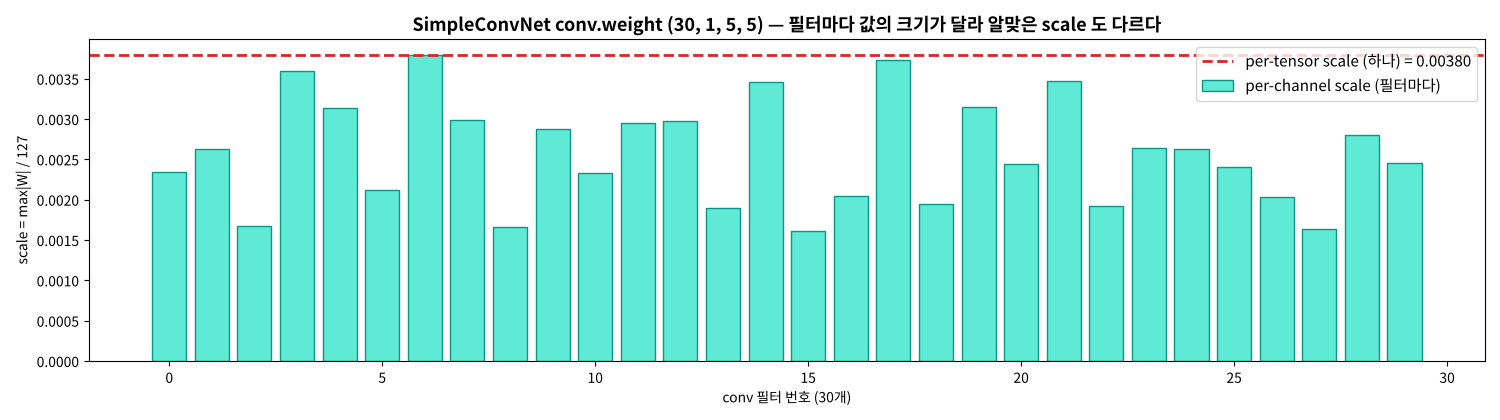

In [ ]:
#@title 🖼 그림 — 필터 30개의 알맞은 scale — 하나로 통일하면 작은 필터가 손해
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f5_perch.png", embed=True, width=860))

**✍️ 직접 구현 5-1** conv weight `W` 의 **per-tensor** 대칭 scale 을 구하세요 (4교시 `sym_scale` 를 써도 됩니다).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 1개).

In [ ]:
#@title 💡 힌트 5-1 — 실행할 때마다 하나씩
show_hint("5-1", "7YWQ7IScIOyghOyytOydmCBtYXh8V3wg7ZWY64KY66W8IDEyNyDroZwg64KY64iV64uI64ukLg==")

In [ ]:
# ✍️ 직접 구현 5-1 — per-tensor 대칭 scale
st_w = None       # TODO

print(f"per-tensor scale = {st_w:.6f}")

In [ ]:
assert abs(st_w - sym_scale(W)) < 1e-12; print("✅", round(float(st_w), 6))

In [ ]:
#@title 🔒 정답 보기 5-1 — 강사가 알려 준 5교시 잠금 코드를 입력하세요
show_answer("5-1", (
    "Ilrv8VMDopZn2adW4mckAQVnLkh6ix4GyUeQdcPHsnLtsgR4imKxYy6vKVFNacgN9Fy8Ut6LGtuk9xPvgEai19cs"
    "iCUKyZcVxlNuNsylLDIydLphO1+S5khyY9Tpi3+K+sO3hs4b7oNLTtE9OiQW1CI8VGbqa6oav0piRs/ZIf/jlvN+"
    "dA8rvgYejIFVYManbYFN2AtK0J82eTJC6ptX2tbGVijWT36VH0FCZEsapqGRk1szV3TdtR9LyJqFIYwbw0kFjH2s"
    "tLV8rDiNvGbeCXqgLf0Dt2cKfwvKiZIYs3w/"
))


**✍️ 직접 구현 5-2** 이번에는 **필터(출력 채널)마다** scale 을 구하세요. `W` 를 `(30, 나머지)` 로 펴고, 행마다 max|W| 를 구합니다. 결과 shape 는 `(30,)`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 5-2 — 실행할 때마다 하나씩
show_hint("5-2", "VyDrpbwgYCjtlYTthLAg7IiYLCDrgpjrqLjsp4ApYCAy7LCo7JuQ7Jy866GcIO2OtOuptCDtlokg7ZWY64KY6rCAIO2VhO2EsCDtlZjrgpjsnoXri4jri6Qg4oCUIGByZXNoYXBlKDMwLCAtMSlgLh7tlonrp4jri6QgbWF4OiBgYXhpcz0xYC4e6rKw6rO8IHNoYXBlIOuKlCAoMzAsKSDsnbTslrTslbwg7ZWp64uI64ukLg==")

In [ ]:
# ✍️ 직접 구현 5-2 — 필터(출력 채널)마다 scale, shape (30,)
sc_w = None       # TODO

print("shape", sc_w.shape, "| 가장 작은 scale", sc_w.min().round(6), "| 가장 큰 scale", sc_w.max().round(6))

In [ ]:
assert sc_w.shape == (30,) and abs(sc_w.max() - st_w) < 1e-12; print("✅ 가장 큰 scale = per-tensor scale")

In [ ]:
#@title 🔒 정답 보기 5-2 — 강사가 알려 준 5교시 잠금 코드를 입력하세요
show_answer("5-2", (
    "AFlhdCoJesG0bZNHYOUIDe+F9kuD6a+xJ93J1k3mdenLNXgvfo4kVv7nUu0iR3vTwFnrfBilOhSRJ8Y/OTcQ4Fdq"
    "XcjxU1hgiPC/UGmHotADA1O/Xac/zaJg9ZXcOlZNWPpd/lN0CzVigrV2iApQ206XlwdeA8m8wRBzzgcQ4sZ4Toid"
    "/PETtVI2iEnhZ0jRSOcl0AHSH1mQYEdbpAgXMZ8PDGasFdTgbK/QhDACmdr1CTwjWZM3BkXyhCVLutgoL+t6NA0Z"
    "DBw6r6Kw0Qdw7HSx0GVoZRp1NAxLtDm2D6E01lZTuCfMtZ3TQmhxbwanIXz/kZ1mxSRMFey/OxIGWY3F/7wYHeTo"
    "I3rw+8N4TXwj6Oqi/fijsQNPi+dP84Q7qZps+J3FNiMSe5UTxrCztHaZrMTWFzk2Zsaus4gCSJZ59bY55TeEDzqN"
    "3BddvMylz02RRyK3VqhxFcO9QP8qQkp/hTiKKKZ+xnzMBP6wJNacbDJp9bo8XYHx/i2GHHQWpdS0fW3fAmdYN/Q2"
    "mGRUCbFd2fwKFh2EQ71WU7D9bbKsdxcHleTUqs+33f8+uTg4U4kv7kfPHdD3PndyGTf7dJisNMGIL6HzqHqCJMod"
    "YjtRzu8yug15UonurKyKFA=="
))


**✍️ 직접 구현 5-3** per-channel 로 양자화 → 역양자화하세요. `sc_w` 를 `(30, 1, 1, 1)` 로 바꿔야 `W (30, 1, 5, 5)` 와 **broadcast** 됩니다. 그리고 두 방식의 MSE 를 비교합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 5-3 — 실행할 때마다 하나씩
show_hint("5-3", "KDMwLCkg7J2EIFcgKDMwLCAxLCA1LCA1KSDsmYAg64KY64iE66Ck66m0IOy2leydhCDrtpnsl6wgKDMwLCAxLCAxLCAxKSDroZw6IGBzY193WzosIE5vbmUsIE5vbmUsIE5vbmVdYC4e7JaR7J6Q7ZmUIOKGkiDsl63slpHsnpDtmZQ6IGBucC5jbGlwKG5wLnJvdW5kKFcgLyBzKSwgLTEyNywgMTI3KSAqIHNgLh5wZXItdGVuc29yIOuKlCBgc3Rfd2Ag66GcIOqwmeydgCDqs4TsgrAu")

In [ ]:
# ✍️ 직접 구현 5-3 — per-channel / per-tensor 왕복 결과와 MSE 비교
sc4 = None        # TODO: (30, 1, 1, 1)
W_pc = None       # TODO: per-channel 왕복
W_pt = None       # TODO: per-tensor 왕복
mse_pt, mse_pc = mse(W_pt, W), mse(W_pc, W)

print(f"per-tensor MSE {mse_pt:.2e} | per-channel MSE {mse_pc:.2e} → per-channel 이 {mse_pt / mse_pc:.2f} 배 정확")

In [ ]:
assert sc4.shape == (30, 1, 1, 1) and mse_pc < mse_pt; print("✅", round(mse_pt / mse_pc, 2), "배")

In [ ]:
#@title 🔒 정답 보기 5-3 — 강사가 알려 준 5교시 잠금 코드를 입력하세요
show_answer("5-3", (
    "wF1BECztvey4VTKZflrE4V9/KL5E86f/SpDTIRa41dXu1HlhADOLkT576mFKT380UzaMlGYctmoa3vM3a8Dp/7Sw"
    "4nAwETpgVp7fCkQdP+2o0KY+b9Y7rEj0B5JXaOMYQEzcfJhyw72TZRtr/S6mElK9j29zGDcEeGHLAGO59fgkG/Ov"
    "bH/NSqZXDd+eYYCovrHEyaeaWddwW5SM7UVbbiGzL2fc2ftMRmOLUvPUJh6YmkTPVRWGXVtGZo9HG44oKsjF+sz9"
    "Zk+RfmSTbIMpNa/1A4dHi2x5FFqat/54iedUmotP1FPT1KnVLdMfpBoTyH5tclwW8oSFAO7BCHFeffWPFHjlc9Qp"
    "OmUhAvDEzjzRbo9j+bd1ztvxOqP5D49/ijidpqpc0yUwYTXhtiSLiexVKcRFAwB7RjL93eUgnGPMtLIvTj7p77gO"
    "ct91JoULqLxiTY4/Ac9y6I+/tRltG8CtbcO+ROKV9KAWA+gUzP8zx9hs+bBr4N6MiWQWKNxLZ81VRn01epJmYYFf"
    "LsiSCvIDJSugiPhNvtaFvvC20NmOCOF79yUP2PIY7GISwgmksXdZ4Nzg4bO1XccAEKk9LfU4Jh4MvfZKwgwL/Fj8"
    "y2FPcupD8qMmOeFZCPhhck0HfYPc0z8g+EdmQEmU/GVFLNN8XHL9OJFi7Lf8V6AgHf8mGARr+1FutbIMqxh0LpQ2"
    "Ng+MGq4bhjdEk4R60a9dtP6KYYO4XbliyUNsd9KqwHsGYVxtxwOhideT5ne6eM0x9n2C6nskEvidgxX51gkgRo0d"
    "hwBNM60A5uFBz5KywMIEvbZuHwe2hAE="
))


**✍️ 직접 구현 5-4** 어떤 weight 에도 쓸 수 있게 `per_channel_scale(W)` 를 함수로 만들고, fc1 weight `(100, 4320)` 에도 적용하세요. Conv · Linear 모두 **0번 축 = 출력 채널**입니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 5-4 — 실행할 때마다 하나씩
show_hint("5-4", "7LGE64SQIOyImOuKlCDtlZjrk5zsvZTrlKkg64yA7IugIGBXLnNoYXBlWzBdYC4ecW1heCA9IDJeKGJpdHPiiJIxKSDiiJIgMS4e64+M66Ck7KSEIOuVjCBgcy5yZXNoYXBlKC0xLCAqKFsxXSAqIChXLm5kaW0gLSAxKSkpYCDigJQgQ29udiDrqbQgKEMsMSwxLDEpLCBMaW5lYXIg66m0IChDLDEpLg==")

In [ ]:
# ✍️ 직접 구현 5-4 — 어떤 weight 에도 쓰는 per-channel scale 함수
def per_channel_scale(W, bits=8):
    # TODO: (C, 나머지) 로 펴서 행마다 max / qmax → broadcast 가능한 모양으로
    pass

W1 = cnn.fc1.weight.detach().numpy()
s1c, s1t = per_channel_scale(W1), sym_scale(W1)
fc1_ratio = mse(np.clip(np.round(W1 / s1t), -127, 127) * s1t, W1) / mse(np.clip(np.round(W1 / s1c), -127, 127) * s1c, W1)
print("fc1 scale shape", s1c.shape, f"| per-channel 이 {fc1_ratio:.2f} 배 정확")

In [ ]:
assert per_channel_scale(W).shape == (30, 1, 1, 1) and s1c.shape == (100, 1) and fc1_ratio > 2; print("✅", round(fc1_ratio, 2), "배")

In [ ]:
#@title 🔒 정답 보기 5-4 — 강사가 알려 준 5교시 잠금 코드를 입력하세요
show_answer("5-4", (
    "vIAhT5+Q7eVFOkL3AyGP4wWRI6BzchqTqZDlwJAYWOeANdenP14nfpgazbVf6w0ZVUT7YgKRgxnbEETJSQNoB9ZY"
    "vJ8Ch805EjrU1Jf275eBQWI4KhX57kZ7t2NpPcNeLkWKfDuWHaOtoXQcn+nGk4pETKuxNk+xmKD/BdiG4W14JgIk"
    "W/21DlheHdXm4y+wE6DKzeyEBTgnCdwnt3uiaFXChxjLs7FkbJh6ZY9FVIdqkzjcOrDPEtnNYDHv2Z+4gGYWHoND"
    "JGio41Hsy/DX80RJpgxkHT9MKVZKGbhG0GJ1+VfGaIeA+foKS7G+O8d3MIdxXRMPrFiOXGTeOkuW6eI3R7L1MsBy"
    "FU9cDyxLjj2A2g/+FWGy4GGIja/Nlb1GeLXUX4vbOfSdgtqo6FQnpGY8j85dSQsqBH1IJHadc1r41Km9SMjmLADZ"
    "ALE0JbcdVapzwcFku8+xVjsWLWS8L61NOs95titdaZ0h4Te6OCjylh8XwsbVeu/quZ97VLNS2wpC++SbmMWCwAAr"
    "g52IE9lRas7tVlJkm037dM4mihKo128vjEVcks3T9E0ZJbtA/L0cf0M8u3gIEpeSXZG4CZWSi1rXnf7+197aDGT3"
    "XSf6QQVwPLJ+iBhkv8cEXmqxYyqsB6uq91t51z+n27M3ZL3DDoTSbziZCNiJjWCtPEpZNqzs+KlLji3EEP1G3CZp"
    "8XcxaDhq22yhIIU6C3Cj1kPJ8rPEO1DiVY8s3yk+9DIXpAeYySutuYwXzfaqnKfkGWIfZcq7nLvUoH3oFZTu4emT"
    "WnPC2rL0CBu8ezS3oJ5Q8OErQ4m7T2ShthvK2fDbi+dawmLBXif3JHEPVYyJI2gNeYH2Be0ZgfQY+RNw/fezzOIA"
    "9m9xlfHuNHT7TcLJBsFO1rWkF7MzOkZLm869drAtRhddkOpbsMpDUSyneM5hLXGS/At1USkiR1trvQmxht0u4tX2"
    "bScxHuDYPUpOms3eidx4RB0/2tVCM0oPK5P/vSE="
))


### 🔁 바꿔보기 — 튀는 필터 하나

필터 하나가 유난히 크면(outlier channel) per-tensor scale 이 그 필터에 맞춰져 **나머지 29개가 모두 손해**를 봅니다. `K` 를 바꿔 보세요.

In [ ]:
K = 10                                          # 1, 3, 10, 30 으로 바꿔 보세요
Wo = W.copy(); Wo[0] *= K
so_t, so_c = sym_scale(Wo), per_channel_scale(Wo)
e_t = mse(np.clip(np.round(Wo / so_t), -127, 127) * so_t, Wo)
e_c = mse(np.clip(np.round(Wo / so_c), -127, 127) * so_c, Wo)
print(f"필터 0 을 ×{K}: per-tensor MSE {e_t:.2e} | per-channel MSE {e_c:.2e} | 차이 {e_t / e_c:.1f} 배")

#### ⚠️ 자주 하는 실수

- `sc_w` (30,) 를 그대로 `W / sc_w` → 마지막 축(5)과 맞추려다 오류 또는 엉뚱한 broadcast. 채널 축을 맨 앞에 두고 `(30, 1, 1, 1)` 로.
- 활성값에도 per-channel 을 쓰려 함 → 다음 층에서 여러 채널을 **더하므로** 채널마다 scale 이 다르면 정수 덧셈이 안 됩니다. 활성값은 보통 per-tensor.

#### 📌 5교시 정리

- per-tensor: scale 1개. 가장 큰 값에 맞춰져 작은 채널이 손해.
- per-channel: 출력 채널(0번 축)마다 scale. weight 의 표준 — ONNX Runtime `per_channel=True`, TensorRT 기본.
- 채널 scale 은 `(C, 1, 1, 1)` 로 만들어 broadcast.

## 6교시 — Clipping 과 Outlier: 범위를 어디까지 잡을까

지금까지는 범위를 **최솟값 ~ 최댓값 (MinMax)** 으로 잡았습니다. 그런데 아주 드문 큰 값 하나 때문에 범위가 넓어지면 나머지 99.9% 의 값이 모두 거친 간격을 씁니다. 범위를 일부러 좁히는 것이 **clipping** 입니다.

> 🎬 **애니메이션** [D1-6 clip 범위 슬라이더](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html#d1-6)
> 애니메이션으로 **예측**하고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

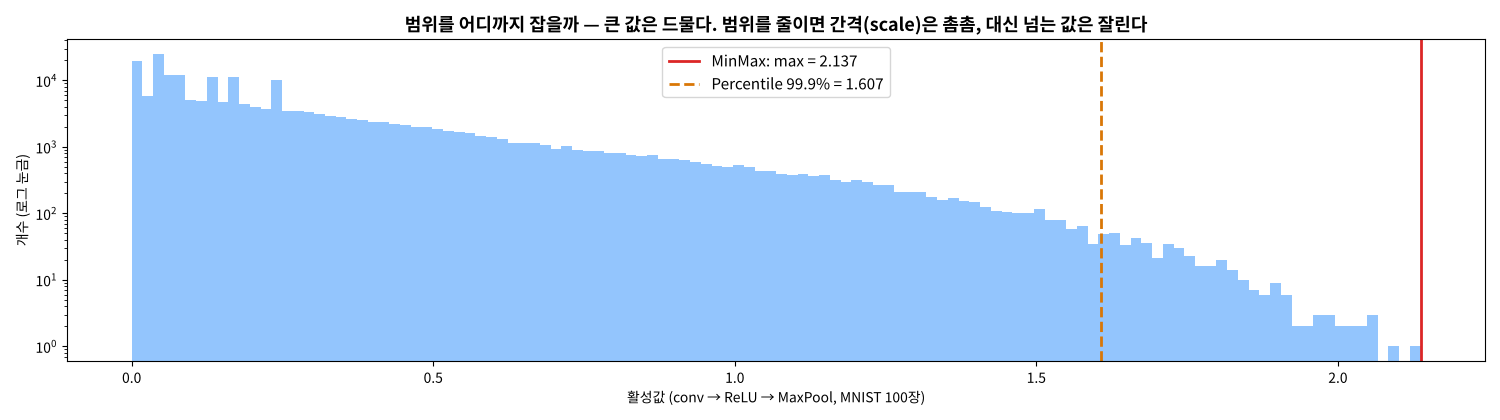

In [ ]:
#@title 🖼 그림 — 활성값 분포 — 큰 값은 아주 드물다 (로그 눈금)
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f6_hist.png", embed=True, width=860))

**✍️ 직접 구현 6-1** 활성값 `A` 의 **99.9 백분위수** `p999` 와, 그보다 큰 값의 비율 `frac_over` 를 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 6-1 — 실행할 때마다 하나씩
show_hint("6-1", "67Cx67aE7JyE7IiY64qUIGBucC5wZXJjZW50aWxlKOuwsOyXtCwgOTkuOSlgLh7sobDqsbTsnYQg66eM7KGx7ZWY64qUIOu5hOycqCA9IOu2iOumrOyWuCDrsLDsl7TsnZgg7Y+J6regIGAoQSA+IHA5OTkpLm1lYW4oKWAu")

In [ ]:
# ✍️ 직접 구현 6-1 — 99.9 백분위수와 그보다 큰 값의 비율
p999 = None       # TODO
frac_over = None  # TODO

print(f"MinMax max = {A.max():.3f} | 99.9% = {p999:.3f} | 넘는 값 {frac_over:.2%} ({int(frac_over * A.size)} 개)")

In [ ]:
assert abs(p999 - 1.6073) < 1e-3 and frac_over <= 0.001 + 1e-9; print("✅ 범위를 25% 줄이면 잘리는 값은 0.1%")

In [ ]:
#@title 🔒 정답 보기 6-1 — 강사가 알려 준 6교시 잠금 코드를 입력하세요
show_answer("6-1", (
    "rXWKvZpZ/YwSjW7/OrxxdXWG7CrRA2754n+w8GUXf75BO6B2NlkXo/JtzoFWXZsLo8vwEMSINBWvPHopchjFZBcb"
    "GZE907VyrmP8osdm/01hmm1h5gZi6HIoxwJkfYve8lrjg+WKudHXdaBO7Cj8pj8OnEi6tc2sNHhptQSeJA9sTCTS"
    "jMW5hc5zwkZ4+WtAwuDIc28HpOH8H4Fk0+ubtzI0BaqJ2KFCvlltOWKe6Kz52fzh8BFPH9ovcbe5Xs5wRN/go6zf"
    "NTSdVj0wBZu+grqchnUZElkfjulmU/yymTHKbx9z416QgZtsHyCOgaETP0m+Hd6X/nkHCkkwr69Wdtd8NFMF67ML"
    "rZ3RKx0tZc1fDLsE9sqN6SPTErhObYUmpt1s4Ou4sOkbaqbthAXV27Akz0icLV892TzTKCifpz4H75Tkt0NFqfop"
    "4LA2lvS+713rjTsjeXS0saTZwwkQTPFHZkUsUPrAaLWInRXWpx6Vwp9x0Ift01Uj2QC5dWtMIbSxSefrf3irq1WN"
    "RAKdkDLpdGF+GSmqBWEK4zUcerEXrrvu9rBFqu3kTfAlyGvqz9ivpGYst59uxqbrGGIJMoIld9Tpe1WnvYXdPIMx"
    "v6Kdc8CNTBn50YWp"
))


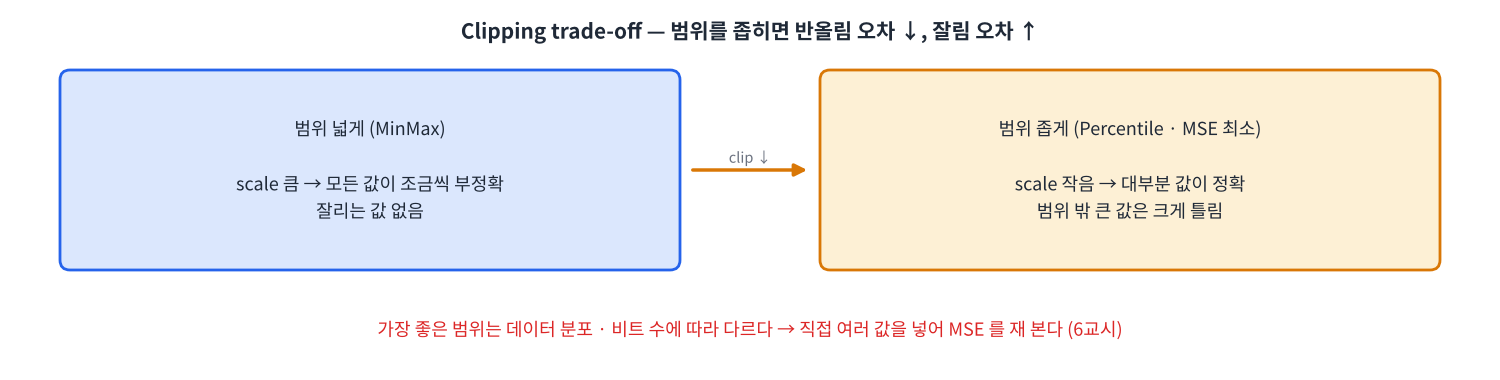

In [ ]:
#@title 🖼 그림 — 범위를 좁히면 반올림 오차 ↓, 잘림 오차 ↑
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f6_tradeoff.png", embed=True, width=860))

**✍️ 직접 구현 6-2** clip 값을 바꿔 가며 MSE 를 재는 함수를 만들고, 최댓값의 5% ~ 100% 범위에서 **MSE 가 가장 작은 clip** 을 찾으세요. 8비트와 4비트를 함께 그립니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-2 — 실행할 때마다 하나씩
show_hint("6-2", "bXNlX2NsaXA6IGBjYWxjX3NjYWxlX3pwKDAuMCwgY2xpcCwgMCwgMioqYml0cyAtIDEpYCDihpIgcXVhbnRpemUgwrcgZGVxdWFudGl6ZSDsl5Drj4Qg6rCZ7J2AIHFtaW4gwrcgcW1heCDrpbwg64SY6rmB64uI64ukLh7qsIEg67mE7Yq466eI64ukIGBjdXJ2ZSA9IFttc2VfY2xpcChBLCBjLCBiaXRzKSBmb3IgYyBpbiBjbGlwc11gLh7qsIDsnqUg7J6R7J2AIOqwkuydmCDsnITsuZjripQgYG5wLmFyZ21pbihjdXJ2ZSlgIOKGkiBgY2xpcHNbLi4uXWAu")

In [ ]:
# ✍️ 직접 구현 6-2 — clip 을 바꿔 가며 MSE, 비트별 최적 clip
def mse_clip(x, clip, bits=8):
    # TODO: [0, clip] 범위 · 2**bits 칸으로 왕복한 MSE
    pass

clips = np.linspace(0.05, 1.0, 96) * A.max()
best = {}
plt.figure(figsize=(10, 3.6))
for bits in [8, 4]:
    curve = None                      # TODO: clips 마다 MSE
    best[bits] = None                 # TODO: MSE 가 가장 작은 clip
    plt.semilogy(clips / A.max(), curve, label=f"{bits} bit  (best clip = max x {best[bits] / A.max():.2f})")
plt.axvline(p999 / A.max(), color="orange", ls="--", label="99.9 percentile")
plt.xlabel("clip / max"); plt.ylabel("MSE (log)"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [ ]:
assert mse_clip(A, best[4], 4) < mse_clip(A, A.max(), 4) and best[4] < best[8]
print("✅ 최적 clip — 8bit:", round(best[8] / A.max(), 2), "× max | 4bit:", round(best[4] / A.max(), 2), "× max")

In [ ]:
#@title 🔒 정답 보기 6-2 — 강사가 알려 준 6교시 잠금 코드를 입력하세요
show_answer("6-2", (
    "/Zha6vy2Jjm2E71PWTdflSdgw+91MkAm6sn5tPHNlpKxYyVBZsWMKkJgjcg8CI1HRxnA6fWAfZPQubRgq67jo9BV"
    "0r0shkS2Lqr9kYYroPl3ZlCJswr8NYZ1NK8rcJJ2wqRqPgby5PhYdDkM2Z/elKw+R9TMpEDQH8+7r1D5iNzDITna"
    "TL6MMXi9yrsqm9p09jh1y7Hrr6ITetEImx+BTep5eMUXvDUSrHrOTzA3kgj8u0BeLlkxnf4SMbMZsOJcPTulfy7v"
    "8j3qqv8kV7Xu6/g6dsJsNo0u82Vgg5z1mdVysM5DjhQYZTiWp+v/TpvVwHAxjpBr+l5o6FA8GVZzRSa8UAyivdpS"
    "RXSRUfn/8x+fSFXvEPFfEOktfcFGpmc8ij4TRDkohpsoUHzUe+9xVqQ6qHrHwJX7kncy9lkTfP8CyakFdLb9Vvtu"
    "adM8X1GCwtVKLOrfpb9qH8HRXcOSarWIIuCH/O5cwnqnASdl8ScEP81FuDqnxcToiyPVIeMwIfOZ8RdO3TzglNuD"
    "vUW2qYv9ktivNoFaHUmekwn8/QXDPXgivyZ2ryAFK3Pl9uEQGDKTS7X3HwO1Zb68kXEKRteA+tWaqA7bBc0qsgdz"
    "DqnGSWXp30Jm3HMJ6ta/itVPapnKP5ufbceeqxPRL5gkPTNF+5VnE5pMc/4oepBf1rGT1IQOFXMJg6CpXWizWWxr"
    "xhfBf/HNcY/NgYKOfcLQb5LWEhCP8RDwZuFaYF8gjT17LvyfEsphtU9IN52hbfctd/krWX1HWew7ZMNkNr/h5U9h"
    "/ftaZyFUHa30TOMQ0UNWdEem3o2/vBI207FWWOCa1oPilkB7n/3BsY1nTFQLHPeoT2WW4Ey2wC0CSThcqg1HjxYJ"
    "O997stv+FfD10I4gJBTYysftypxnAMGg0XBEdhL2K7YzLf8jNhevJ5ji3HVRWtxSdeLx6DdM6ehVHEXlO/plOHD4"
    "PtUKfFV0jK+wix/25sZItr+yaG9v9fmVkelk0fU+zxPP2AAIrgjVatH4hUrDbveJjad3YH3DjiMC/QKD+VA5qHEr"
    "wxWhvhnOj2aTjbqFMWxqnoWvTSIYfpL27D1qIc5r9hiSohXNFP60deMKFCQ0rZpmIB2N0FRHAQbJzr5paT0gk6al"
    "4WD8Vq8uvIpwBd0ENAPWcpstGbDynzFECwC59ymQCv0GsBACZlk/ZcuwYcwqG7fnQlhWp72mlAoAAuD5XKUiEeBy"
    "NF0gzvhj1RUlZUzEwuAIrAQCv5m6joIMolOmWvIUPGWWyc0oikH7ALhEA3hWL6eMIt7xlAyRR/ZEW9aFMdS1yuru"
    "w1x0GFC8xqmCuGhCR+qWVKOyyyfPeLqFFtcJrfM5H0W2Am/ZzTD/R0mkXZ70s59z2jeKN93beMf1vkPIIx7+/BNZ"
    "3flMdqtZvNiYCUPn4WUMOX3xroz2aPDKZMrJxyriAizHGTGQ+vW+"
))


### outlier 가 있으면?

센서 노이즈나 특이한 입력 때문에 아주 큰 값이 **하나** 섞였다고 해 봅시다.

**✍️ 직접 구현 6-3** `A` 의 첫 값을 최댓값의 20배로 바꾼 `A_out` 에 대해 **MinMax** 와 **99.9% Percentile** 범위로 8비트 양자화하고, MSE 를 두 가지로 재세요.

- `all` — 432,000 개 전체
- `rest` — outlier 1개를 뺀 나머지 431,999 개 (모델 대부분이 실제로 쓰는 값)

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-3 — 실행할 때마다 하나씩
show_hint("6-3", "cm91bmR0cmlwKHgsIGNsaXApOiDrspTsnIQgWzAsIGNsaXBdIOycvOuhnCBxdWFudGl6ZSDihpIgZGVxdWFudGl6ZSDtlZwg67Cw7Je07J2EIOuPjOugpOykjeuLiOuLpC4eTWluTWF4IOydmCBjbGlwIOydgCBgQV9vdXQubWF4KClgLCBQZXJjZW50aWxlIOydgCBgbnAucGVyY2VudGlsZShBX291dCwgOTkuOSlgLh5vdXRsaWVyIOuKlCAw67KIIOybkOyGjCDigJQg64KY66i47KeA66eMIOu5hOq1kO2VmOugpOuptCBgWzE6XWAg66GcIOyemOudvCBNU0Uu")

In [ ]:
# ✍️ 직접 구현 6-3 — outlier 하나: MinMax vs Percentile, 전체(all) / 나머지(rest) MSE
A_out = A.copy(); A_out[0] = A.max() * 20

def roundtrip(x, clip):
    # TODO
    pass

r_mm = None                    # TODO: MinMax
r_pc = None                    # TODO: Percentile 99.9
mm_all, pc_all = None, None    # TODO: 전체 MSE
mm_rest, pc_rest = None, None  # TODO: outlier 를 뺀 MSE

print(f"범위   MinMax {A_out.max():.1f} | Percentile {np.percentile(A_out, 99.9):.3f}")
print(f"all  : MinMax {mm_all:.2e} | Percentile {pc_all:.2e}")
print(f"rest : MinMax {mm_rest:.2e} | Percentile {pc_rest:.2e} → 나머지 값은 Percentile 이 {mm_rest / pc_rest:.0f} 배 정확")
print(f"outlier 하나: 원래 {A_out[0]:.1f} → MinMax {r_mm[0]:.1f} | Percentile {r_pc[0]:.2f}")

In [ ]:
assert pc_rest < mm_rest and pc_all > mm_all
print("✅ 전체 MSE 는 MinMax 가 낮지만, 나머지 431,999 개는 Percentile 이", round(mm_rest / pc_rest), "배 정확")

In [ ]:
#@title 🔒 정답 보기 6-3 — 강사가 알려 준 6교시 잠금 코드를 입력하세요
show_answer("6-3", (
    "Kc2YwISv9KFqMJ85AnWHpWfDvjjl5FpCFM/DhnuYCgCnwtwr6NFTq5wYP1aB6fHSLdeB1YPvKgyl9a1ekPYFQhga"
    "oE/0PQCIaxGdd2jdRT8nHymnTX1jaHOWl1oe+y2wH2LnSParkAt6VOKPRQwgq/Ihhp4zWXL9biUp567Ps52wHiLS"
    "KxResnF4jfoS4+m2BqOiD+FEoo06+nZwr5EwuN+nULXqFbVjUuL7BDsdlBA0eKPikhqiF8mJJgy3WzpsUnPDhcvW"
    "LqFrLeLKdKR8Wnf0wwzM+lfyRIQEitzOlsl/M1ZT/hXQi4oUvVjF6zTBYm4ejj3iovPoKO9CQC2T7odUQaZlG6qM"
    "nt6GahFyYG5HyOQlzJaOwLRuvy2S3xNtleoaTcMybMLibSd5Z8Sbwp8P3yJLLexN+LktEmWPAccYweagDWTcnbCR"
    "Wm0GTzSlFcFSZqqab3Hdz0O+R2ZDk55YuUvCwodLP3JxR8mLLO1nE3v2XUcjV7rPjwnLHarmmFA8X3PSlB7iobsq"
    "L1r3OSDDHFAMnKl3FnGllOK7oEaBoX+2S9KvfjRC6aJ17ioAD3VR0fT/k7mzcx/ayfW0EN6phW15efVCHbYxVnij"
    "Auk6fZBFhyNcGod8NBQBZcjWoI1w0BTWdfnhGB8RGSrMwgn+y+E+mbeUlaTL4MkAhUICf1rbBsr5tQ6DRpyzRfoS"
    "6F2vJ6V6EjcX2jrymBGXel8QR8HcYWwRz0J4pujLKaJciQScwLKqgult+wIbR/QSuu7FZLpaDywV3g27of2B8Jzq"
    "vMXe+Qj4onT1RarhE4g12+SvvCJL1gMeOChDQ/rODcUhcEA4TNcAwEj7//aTY/omo1qXhXxkfFDG3tDydmjUv7V9"
    "DIqE4h+s8bq4fx0L4oGok7U3UFVd1+nO2SD/xWIjguOtmghVehWVu8kMiJt94cRLNZFsp/rWfPmQxt+yqsrI933e"
    "FAcm/Huij4Pni5+LQ40xSw0ZvrOmo52ILUD7nHJ998Ddu3z283Imtrqwrg5gpFG4JTGdl61Zyt6RpgUiltNO8sPB"
    "ANW17l/BKi0qqOYJUNix1GTxMbEIIpX+apAOOQJF8KKSkbaveUI6wlkJ289QA5js7kbnV9vmYmPWOi1+89WftLF2"
    "Eq3VjsDuYEay+khM5d/mIJPi9GCb4bVjUMi2LjQa6JVVQAy37PqBAr9YggyYH9S2mCyaAHY1jN1U+vq3ri/bOfrq"
    "c3se41tCTHDGUSSqIA6k7JINvFkeJ0P3HJhM4/SCBkgt7pzDnnmWXsYOH0rW2uWzd3aZwwwVKtCBsjZrD59yR7k2"
    "WPGfYzvrSAC1KXV3xKimLsbDOlvFWm1gAn46jEPwXL7etFSGypzA/8tD82nKXy6mEBt/PvDizCxajHvF0f9wVgQy"
    "LvV+/EMG/66gkEssQSfP9mOzGNEG1FxGfH4BzI8bTOh6zIuvNFHmfMpO8x/e1xviymBi9Tkf4fyb0ezOSUe1tn/m"
    "EgRwW5OhWSg3wD+kSGzQzYfs893lWAZgcgfxn5s/7qokDGU9YIO8X3OCh0DzVQA/uYsMmJP+Geoh6kIvLgI1NM3F"
    "5Wi0msu//bvLI5Pui+wb0jeBY9o047M+zcaG6Vbz2TZ6KIhb6loY6tchV23eOLQBt4fBvz8Q3ggZj+AcITe/mhzh"
    "889lebqglmsGL2rvHYv41UCgKsz8i9dSp6nY6KIr8xApdpw9r1N5IUnQKYNsoUmgl9+APGNDKkrV6H+MuDwlvJz+"
    "ZMZel7hxAImoLZs+2nNL6o+0GeJ3irfQyig0kGGGM/aXMzdmmZQEHC+jfZWExlww1uWls9aPLqhSv1CXGQ=="
))


### Calibration 방법 미리 보기 (Day 2)

활성값의 범위는 **보정(calibration) 데이터**를 모델에 흘려 보내 정합니다. ONNX Runtime 의 `CalibrationMethod` 는 오늘 실험한 것과 같습니다.

| 방법 | 범위 정하는 법 | 오늘의 실험 |
|---|---|---|
| `MinMax` | 본 값의 최솟값 ~ 최댓값 | 3 · 4교시 |
| `Percentile` | 99.9% 같은 백분위 | 문제 6-1 · 6-3 |
| `Entropy` | 원래 분포와 양자화 분포의 차이(KL) 최소 | (Day 2) |
| (MSE 최소) | 오차가 가장 작은 clip 탐색 | 문제 6-2 |

### 🔁 바꿔보기 — 백분위 바꾸기

`PCT` 를 바꿔 보세요. 8비트 · 원래 `A` 에서 어떤 백분위가 가장 좋은가요?

In [ ]:
PCT = 99.99                                     # 99, 99.9, 99.99, 100 으로 바꿔 보세요
c = np.percentile(A, PCT)
print(f"{PCT}% → clip {c:.3f} | 8bit MSE {mse_clip(A, c):.2e} | 4bit MSE {mse_clip(A, c, 4):.2e}")

#### ⚠️ 자주 하는 실수

- "Percentile 이 항상 MinMax 보다 좋다" → 아닙니다. outlier 가 없고 비트가 넉넉하면 MinMax 가 나을 수 있습니다 (문제 6-2).
- 보정 데이터를 너무 적게 · 한쪽으로 치우치게 고름 → 실제 입력의 범위를 못 봅니다. 실제 현장 이미지와 비슷한 것을 수백 장.

#### 📌 6교시 정리

- 오차 = 반올림 오차(범위 안) + 잘림 오차(범위 밖). 범위를 좁히면 앞이 줄고 뒤가 는다.
- 최적 범위는 **데이터 분포와 비트 수**에 따라 다르다 — 측정해서 고른다.
- outlier 하나에 MinMax 는 나머지 값 전체의 정밀도를 잃는다. 어떤 지표로 비교할지(전체 MSE · 대부분 값 · 모델 정확도)를 먼저 정한다.

## 7교시 — 정수 연산 추론: INT8 × INT8 → INT32

지금까지는 양자화한 값을 다시 실수로 되돌렸습니다. 진짜 INT8 추론은 **곱셈 · 덧셈을 정수로** 합니다. 대칭 양자화(zp = 0)면 식이 간단합니다.

$$y = W x + b \;\approx\; (s_w W_q)(s_x x_q) + b = s_w s_x \left( W_q x_q + \frac{b}{s_w s_x} \right)$$

괄호 안은 **모두 정수**입니다. 실수 곱셈은 맨 마지막 `× s_w s_x` 한 번뿐입니다.

> 🎬 **애니메이션** [D1-7 정수 행렬곱](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html#d1-7)
> 애니메이션으로 **예측**하고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

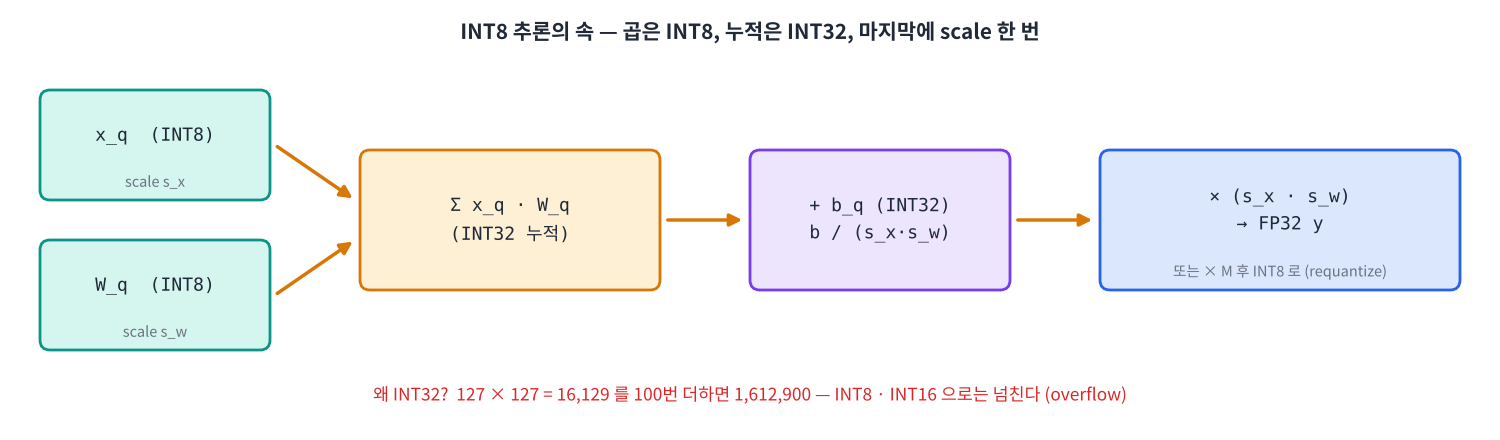

In [ ]:
#@title 🖼 그림 — INT8 곱 → INT32 누적 → + INT32 bias → × scale
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f7_intmm.png", embed=True, width=860))

SimpleConvNet 의 마지막 층 `fc2` (100 → 10) 를 정수로 계산해 봅니다. 입력은 fc1 → ReLU 의 출력 `H` (100장 × 100).

In [ ]:
with torch.no_grad():
    H = F.relu(cnn.fc1(cnn.pool(F.relu(cnn.conv(X))).flatten(1))).numpy()   # (100, 100)
W2 = cnn.fc2.weight.detach().numpy()                                         # (10, 100)
b2 = cnn.fc2.bias.detach().numpy()                                           # (10,)
y_fp = H @ W2.T + b2                                                         # FP32 정답 (100, 10)

sx, sw = sym_scale(H), sym_scale(W2)
xq, Wq = sym_quantize(H, sx).astype(np.int8), sym_quantize(W2, sw).astype(np.int8)
print("xq", xq.shape, xq.dtype, "| Wq", Wq.shape, Wq.dtype, f"| sx {sx:.4f} sw {sw:.5f}")

**✍️ 직접 구현 7-1** INT8 끼리 그대로 곱해 더하면 넘칩니다. 두 배열을 **INT32 로 넓힌 뒤** 행렬곱해 `acc` 를 만드세요. 결과의 최댓값이 INT16 범위(32,767)도 넘는지 확인합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-1 — 실행할 때마다 하나씩
show_hint("7-1", "6rOx7ZWY6riwIOyghOyXkCDrkZAg67Cw7Je07J2EIGAuYXN0eXBlKG5wLmludDMyKWAg66GcIOuEk+2emeuLiOuLpC4eeHEgKDEwMCwgMTAwKSDCtyBXcSAoMTAsIDEwMCkg4oaSIOqysOqzvCAoMTAwLCAxMCkg7J20IOuQmOugpOuptCBXcSDrpbwg7KCE7LmYIGAuVGAuHu2WieugrOqzseydgCBgQGAu")

In [ ]:
# ✍️ 직접 구현 7-1 — INT32 누적 행렬곱
acc = None        # TODO

print("acc", acc.shape, acc.dtype, "| 범위", acc.min(), "~", acc.max(), "| INT16 최대 32,767")

In [ ]:
assert acc.dtype == np.int32 and acc.shape == (100, 10) and np.abs(acc).max() > 32767
assert np.array_equal(acc, xq.astype(np.int64) @ Wq.astype(np.int64).T); print("✅ INT32 누적 — 넘침 없음")

In [ ]:
#@title 🔒 정답 보기 7-1 — 강사가 알려 준 7교시 잠금 코드를 입력하세요
show_answer("7-1", (
    "LRbwfCvSa9A/2z5Do0fgqqEVe8v7vFSykKIapCVNvWN0ucNksRw36hz1Id08r1M4jsBAf8B8TcT8byFu7S+PIDe/"
    "+dA52DLv05M4rD/2Fszq2uGn40MJ+SOl1S7P1T+O5qYOdLOAQlSLftqKGRngU6gSULHBiXLA6YCq/5PEbzHCU+pc"
    "lukbdFWYpYjmkhEh+afunVLInXVr7T5j4yyci1GttjTdKyXOYQ0N12amvMR7FD5rq0K8lU1SR36baG979WK0b3/7"
    "ZkSz0HtAA3Yc9NzvMbL5/Vs1mMnSSzdooQB80QAtDwBMY+fdBzWoxWlnh2TZ2x6vivLR7apTnU8h6WtdBPIh/IUn"
    "zPPrbhJ44wAuOcU2mUHzhxqRUrRYDHpwRXwHSbowZNfvGTVbISzM2gXKC18gqBZ0tIHe6f+wVfHENkyvT1Oo7jR6"
    "24BYtyBGsND+an8FNI09kf1d+QfkQ+ikJ7fCjQycLnWzZSUn+4k1tDVDixfQXwc2rk/luLxVf3TNDd141Iy1u5Si"
    "Xi2of7Gu/AESgT8GZHZ3xAY7iBYH5yTOytuLYOhyjQ=="
))


**✍️ 직접 구현 7-2** bias 도 같은 단위(`s_x · s_w`)의 **INT32** 로 바꾸세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 7-2 — 실행할 때마다 하나씩
show_hint("7-2", "YWNjIOydmCAx7Lm4ID0gc194IMK3IHNfdyDigJQgYmlhcyDrj4Qg7J20IOuLqOychOuhnCDrgpjriJXri4jri6QuHuuwmOyYrOumvCDtm4QgYC5hc3R5cGUobnAuaW50MzIpYC4=")

In [ ]:
# ✍️ 직접 구현 7-2 — bias 를 INT32 로
bq = None         # TODO

print("b2 :", b2.round(4))
print("bq :", bq)

In [ ]:
assert bq.dtype == np.int32 and np.allclose(bq * sx * sw, b2, atol=sx * sw); print("✅ bias 는 INT32 — 8비트로 줄이지 않는다")

In [ ]:
#@title 🔒 정답 보기 7-2 — 강사가 알려 준 7교시 잠금 코드를 입력하세요
show_answer("7-2", (
    "TpWwfGrAcOU8tBv6oqiyY7q3Nuh7+XiH/4TuPQ1OV8aXCEuew+ZOU7LAlg9Y6VhUh9rpgwBqTSD++xTiOJtiFYwY"
    "SHkGb+LkIYfogHR4N1S5ozdTSfYVJH458I7aNlrvRaFFMuUGPiy2l613Wr1C1oXiHvcPRIUrCH91Z7KWZgR3/rkx"
    "XFlWBwt5oCTZGKslVX/45V1MceacGQ421slRRy5Xza1/BjUOIdbL07mSbuLQ2YIoxVWOr6Qcgkm+JYL498qqunyl"
    "Vptf2e1Cb5nSgjdqes0eh3lA5tJxlzKvKtNdWv1awB5xmUmYTgJrlhjRPxTVTPzIXD6nRaEQqXmucfv149xyPtWW"
    "zhghNVAb/07um031UptHx3UmHLh7dda4d3K7l9x6Z8ZAAqpM3m/15pUZV6oNpiiLiKdxi0WIc35ESZqVwnGk3OZ+"
    "13XkX5P3eS64T5FQd/GJ91qikTkjGuc="
))


**✍️ 직접 구현 7-3** 정수 결과를 실수로 되돌려 `y_int` 를 만들고, FP32 결과와의 최대 차이 · 예측 일치율을 구하세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 7-3 — 실행할 때마다 하나씩
show_hint("7-3", "7KCV7IiYIOqysOqzvCAoYWNjICsgYnEpIOyXkCBzX3ggwrcgc193IOulvCDtlZwg67KIIOqzse2VmOuptCDsi6TsiJguHuyYiOy4oSA9IGBhcmdtYXgoMSlgIOKAlCDrkZAg6rKw6rO87J2YIOyYiOy4oeydtCDqsJnsnYAg67mE7Jyo7J2EIGAubWVhbigpYCDsnLzroZwu")

In [ ]:
# ✍️ 직접 구현 7-3 — 정수 결과를 실수로, FP32 와 비교
y_int = None      # TODO
max_err = None    # TODO: |y_int − y_fp| 의 최댓값
agree = None      # TODO: 예측 일치율

print(f"logits 범위 {y_fp.min():.2f} ~ {y_fp.max():.2f} | 최대 차이 {max_err:.4f} | 예측 일치율 {agree:.2f}")

In [ ]:
assert max_err < 0.2 and agree == 1.0; print("✅ 정수 연산만으로 FP32 와 같은 예측")

In [ ]:
#@title 🔒 정답 보기 7-3 — 강사가 알려 준 7교시 잠금 코드를 입력하세요
show_answer("7-3", (
    "lIF3Y9E18gzg6ouVFuh4JW2Uj5OKFahIf4154PJw5OeXGOFXTNdKfBAEEiqYkOV0nCxNbLgpPJlRpxsgLfCfT6jX"
    "S0zxl8OJ0P+I74mMGjWT+qDy4XlQobQ4qm22oD7S6DULzmu9BwvtOqgnlMjTt9q7iJXbUydyqvNxq3Jkq5cr1XLO"
    "nSWnadz4daYZPETBPBhVclOunIgK2xCbdGr+ZqFbtsm1grvb9BpfiDa+afuL1M4W2PzWSmFBzxSKFZfzX9h4QDFd"
    "2XpoBxY0RtdXmkOOVu+wlev2m7kFc7hADBnLcMSUkAJ840/rcz/COsizgzwZwn4OLSBrt8+iYi/9pM15D5srEXmK"
    "KLxlio7NGBuoB3sy4pV77zAuPmRES1S9SXVHywD2T8Zds2X9KcRxqERpwZoCgrZLsy3xHa0IJmnHbfxM/AqYaToj"
    "ZzF3bcQt5azbay3iG/EhFm/zRRte7LugCHYPcQagl8mIFjwLKajtm3kyLpgBRZmMA/tT7pkYzdgDfXU+Ml8Du0Sm"
    "EOkxsHsHB//LZzcuqtQ7W4SANDLlhp3Xoey8aadLPUtW8RPUfNMRpWfRoAYEOIicHnCwJ1eWwc9Vbr8PxTnwWr23"
    "A4WcIF2EyxEJXhimnnCJKF+UjThHtSBBwtL3xcHC+zA8RU9l+fHvdmGFWOQbhuO3D9CeYKJxQwk="
))


### 다음 층으로 넘기려면 — requantize

출력을 다음 층의 INT8 입력으로 바로 넘기려면 실수로 되돌리지 않고 `M = s_x · s_w / s_y` 한 번만 곱해 새 scale `s_y` 의 INT8 로 바꿉니다. 실제 하드웨어는 `M` 도 '정수 곱 + 비트 시프트' 로 계산해 실수 연산을 아예 없앱니다.

**✍️ 직접 구현 7-4** 출력 scale `sy` (대칭) 를 구하고, `M` 을 곱해 INT8 출력 `yq` 를 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-4 — 실행할 때마다 하나씩
show_hint("7-4", "7Lac66ClIHNjYWxlIOydgCDrjIDsua06IGBzeW1fc2NhbGUoeV9mcClgLh5NID0gc194IMK3IHNfdyAvIHNfeS4eKGFjYyArIGJxKSDDlyBNIOydhCDrsJjsmKzrprwg4oaSIOKIkjEyNyB+IDEyNyBjbGlwIOKGkiBgbnAuaW50OGAu")

In [ ]:
# ✍️ 직접 구현 7-4 — requantize: INT32 결과 → 새 scale 의 INT8
sy = None         # TODO
M = None          # TODO
yq = None         # TODO

print(f"M = {M:.6f} | yq {yq.dtype} {yq.shape} | yq × sy 와 FP32 최대 차이 {np.abs(yq * sy - y_fp).max():.4f}")

In [ ]:
assert yq.dtype == np.int8 and np.abs(yq.astype(np.float64) * sy - y_fp).max() < 2 * sy; print("✅ requantize 완료")

In [ ]:
#@title 🔒 정답 보기 7-4 — 강사가 알려 준 7교시 잠금 코드를 입력하세요
show_answer("7-4", (
    "59tO10x+ORsEwje9UyD+cOjn+exyPHPpsqgO2kKNKhbfw73eQLewkSc7HVl7G1BZPbh6tYne4Mg3W0aBnfXvKO5W"
    "aJK1GxkL5rfWDWAOn3FibQPQKBCmgjhJtELVJcMVqef9lHVoHkn5ac7XNsfQxXWv3m3A0RE8mDQx4QvRDYG/U43B"
    "QGiKTF/UjKrZ5BQUMtgUG1kcvhMsTxwAWkkMOGk9l5jIRCLn88c3rtFGZ0gdXsBkCa5GGNSLUfjlYcCU0ui9ZNbl"
    "FCncg+F9K8Jt4S1wo+Zi5zfmx9WEGGv5aLQyHaRNUWmB7cUT9BeCcz0dgLSAQEWiOGExVTsu/UCYvVk8+gLBfK5D"
    "mh0Wb+gLxNE/MF1OUX2oi47Dh87lJiW5oeGuRrTdpkO4QwtZ9XixalKA0zy7pMukRNaNn+s9AN5CFZ45c/yOC7OC"
    "QfattRW4ILAmIBoOO+AIskFN7hdfA+nXI4B7E/OA4PuJUXHdoEW7ujSEghvht8I9e5vLrv7hJvaYvcy1dL5Zis8B"
    "bz/cmTr+sCGiemz0W31LMtjfIFWSwSi9Rizoq2VnyrDho1432sPPPhGaegmT9fVNODcSqCEEEYVnsD9XRsfaF/kp"
    "72vUuT7aPR0LX9fnFLR2K8n0XJQApHehP1IrackKnvgbGQSaI6bvSsQ/VvrZ80EJ6ze4Z8mFl1Y55fE28MnPnmT7"
))


### 🔁 바꿔보기 — 비대칭이면 식이 길어진다

활성값을 비대칭(zp ≠ 0)으로 하면 `(x_q − zp)` 때문에 `W_q · zp` 같은 항이 추가로 생깁니다. 아래 셀의 `ZP` 를 바꿔 결과가 같아지는지, 어떤 항이 더 필요한지 보세요.

In [ ]:
ZP = 20                                         # 0, 20, 64 로 바꿔 보세요
xq_a = xq.astype(np.int32) + ZP                                   # 비대칭처럼 zp 만큼 밀린 입력
acc_naive = xq_a @ Wq.astype(np.int32).T                          # zp 를 무시하고 곱함
acc_fix = acc_naive - ZP * Wq.astype(np.int32).sum(axis=1)        # 보정 항: zp × (W 행의 합)
print("보정 없이 같은가:", np.array_equal(acc_naive, acc), "| 보정 후 같은가:", np.array_equal(acc_fix, acc))

#### ⚠️ 자주 하는 실수

- 곱하기 전에 INT32 로 넓히지 않음 → NumPy `int8 @ int8` 은 int8 로 계산되어 조용히 넘칩니다.
- bias 를 INT8 로 양자화 → bias 의 scale 은 `s_x · s_w` 로 정해져 있어 INT8 에 안 들어갑니다. 항상 INT32.

#### 📌 7교시 정리

- 대칭이면 y = s_w s_x (W_q x_q + b_q). 괄호 안은 전부 정수.
- 곱은 INT8, 누적 · bias 는 INT32, 마지막에 scale 한 번 (또는 M 으로 requantize).
- 비대칭 zp 는 보정 항을 추가로 만든다 — weight 를 대칭으로 두는 이유.

## 8교시 — 미니 프로젝트: 손으로 만드는 INT8 SimpleConvNet · 채점

오늘 만든 함수로 SimpleConvNet 의 **weight 3개(conv · fc1 · fc2)** 를 양자화하고, 비트 수와 granularity 에 따라 정확도가 어떻게 변하는지 비교합니다. 양자화한 weight 를 다시 실수로 되돌려 PyTorch 로 실행하는 방법을 **fake quantization** 이라고 합니다 (Day 4 QAT 의 바탕).

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | `my_quant.py` — 오늘의 함수 4개를 파일로 | 20 |
| 2 | `fake_quant_weight(W, bits, per_channel)` | 20 |
| 3 | 6가지 조합 평가 (8 · 4 · 2 bit × per-tensor / per-channel) | 20 |
| 4 | INT8 모델 크기 계산 (weight + scale + bias) | 20 |
| 5 | 결과표와 배포 설정 고르기 | 10 |
| 6 | 결과 해석 (마크다운 답변) | 10 |

과제 끝의 **채점 셀**을 실행하면 자동 채점 점수와 **정답 열람 기록**이 나옵니다(과제 6 은 강사 채점). 제출은 채점 셀 결과가 보이는 상태로 이 노트북을 공유합니다.

> 미니 프로젝트에는 **정답 보기 셀이 없습니다.** 힌트만 보고 완성하세요. 정답 노트북은 제출 마감 뒤 공개합니다.

> 🎬 **애니메이션** [D1-8 INT8 CNN 조립](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/animation.html#d1-8)
> 애니메이션으로 **예측**하고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

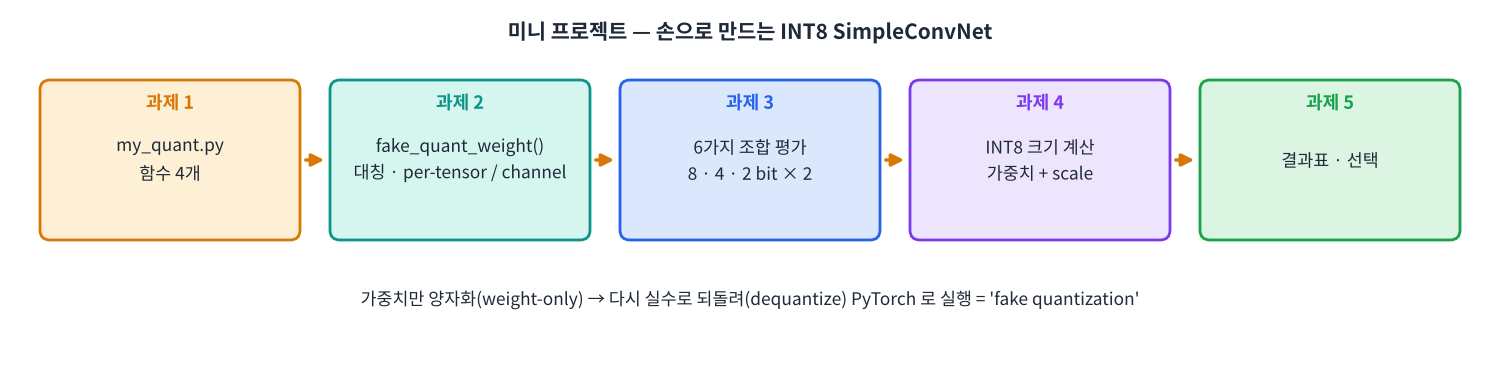

In [ ]:
#@title 🖼 그림 — 미니 프로젝트 흐름 — 함수 파일 → fake quant → 평가 → 크기 → 선택
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day1/img/f8_project.png", embed=True, width=860))

### 과제 1 — `my_quant.py` (20점)

오늘 만든 함수 4개를 **파일**로 저장합니다. Day 2 에서 ONNX Runtime 결과와 숫자를 비교할 때 `import my_quant` 로 다시 씁니다. 3 · 4교시에 만든 함수를 옮겨 적고 실행하면 파일이 만들어집니다.

**✍️ 직접 구현 8-1**

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-1 — 실행할 때마다 하나씩
show_hint("8-1", "M+q1kOyLnCBgY2FsY19zY2FsZV96cGAgwrcgYHF1YW50aXplYCDCtyBgZGVxdWFudGl6ZWAsIDTqtZDsi5wgYHN5bV9zY2FsZWAg7J2EIOq3uOuMgOuhnCDsmK7quLDrqbQg65Cp64uI64ukLh5gJSV3cml0ZWZpbGUgbXlfcXVhbnQucHlgIOuKlCDshYDsnZggKirssqsg7KSEKirsnbTslrTslbwg7ZWp64uI64ukLh7tjIzsnbwg7JWI7JeQ7ISc64+EIG51bXB5IOqwgCDtlYTsmpTtlZjrr4DroZwgYGltcG9ydCBudW1weSBhcyBucGAg66W8IOuCqOqyqCDrkZDshLjsmpQu")

In [ ]:
%%writefile my_quant.py
"""QP Day 1 — NumPy 양자화 함수 모음"""
import numpy as np

def calc_scale_zp(xmin, xmax, qmin=0, qmax=255):
    # TODO: 3교시 문제 3-1
    pass

def quantize(x, scale, zp, qmin=0, qmax=255):
    # TODO: 3교시 문제 3-2
    pass

def dequantize(q, scale, zp):
    # TODO: 3교시 문제 3-3
    pass

def sym_scale(x, bits=8):
    # TODO: 4교시 문제 4-1
    pass

In [ ]:
import importlib, my_quant
importlib.reload(my_quant)                      # 파일을 고쳐 다시 저장했다면 다시 읽기
print(my_quant.calc_scale_zp(-1, 3), my_quant.quantize([0.0, 3.0], 4 / 255, 64))

### 과제 2 — `fake_quant_weight` (20점)

weight 를 **대칭** 양자화 → 역양자화한 배열을 돌려주는 함수입니다. `per_channel=True` 면 5교시 방식(0번 축마다 scale). 결과 dtype 은 입력과 같은 float32 로 맞춥니다.

**✍️ 직접 구현 8-2**

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 8-2 — 실행할 때마다 하나씩
show_hint("8-2", "cW1heCA9IDJeKGJpdHPiiJIxKSDiiJIgMSAo64yA7LmtKS4ecGVyX2NoYW5uZWwg7J2066m0IDXqtZDsi5wgYHBlcl9jaGFubmVsX3NjYWxlYCDqs7wg6rCZ7J2AIOuwqeuylSwg7JWE64uI66m0IO2FkOyEnCDsoITssrQgbWF4IO2VmOuCmC4eMCDsnLzroZwg64KY64iE64qUIOqyg+ydhCDrp4nsnLzroKTrqbQgYHMgPSBucC5tYXhpbXVtKHMsIDFlLTEyKWAuHnJvdW5kIOKGkiBjbGlwKOKIknFtYXgsIHFtYXgpIOKGkiDDlyBzLCDrp4jsp4Drp4nsl5AgYC5hc3R5cGUoVy5kdHlwZSlgIOycvOuhnCBmbG9hdDMyIOycoOyngC4=")

In [ ]:
# ✍️ 직접 구현 8-2 — 대칭 fake quantization (양자화 → 역양자화)
def fake_quant_weight(W, bits=8, per_channel=False):
    # TODO
    pass

for b in [8, 4, 2]:
    print(f"{b} bit: per-tensor MSE {mse(fake_quant_weight(W, b), W):.2e} | per-channel MSE {mse(fake_quant_weight(W, b, True), W):.2e}"
          f" | 서로 다른 값 {len(np.unique(fake_quant_weight(W, b)))} 개")

### 과제 3 — 6가지 조합 평가 (20점)

`evaluate(bits, per_channel)` 이 모델을 복사해 weight 3개를 fake quant 로 바꾸고, 100장에 대해 **정확도 · FP32 와의 예측 일치율 · logits 최대 차이**를 돌려주게 완성하세요.

**✍️ 직접 구현 8-3**

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 8-3 — 실행할 때마다 하나씩
show_hint("8-3", "YGNvcHkuZGVlcGNvcHkoY25uKWAg7Jy866GcIOuzteyCrOuzuOydhCDrp4zrk6TslrTslbwg7JuQ656YIOuqqOuNuOydtCDrsJTrgIzsp4Ag7JWK7Iq164uI64ukLh5gbS5jb252YCwgYG0uZmMxYCwgYG0uZmMyYCDsnZggd2VpZ2h0IOulvCBudW1weSDroZwg6rq864K0IGZha2UgcXVhbnQg4oaSIGBsYXllci53ZWlnaHQuY29weV8odG9yY2guZnJvbV9udW1weSguLi4pKWAuHmB0b3JjaC5ub19ncmFkKClgIOyViOyXkOyEnCDrsJTqvrjqs6Ag7Iuk7ZaJ7ZWp64uI64ukLh5hY2Mg64qUIGxhYmVscyDsmYAsIGFncmVlIOuKlCBwcmVkX2ZwMzIg7JmALCBtYXhfZGlmZiDripQgbG9naXRzX2ZwMzIg7JmAIOu5hOq1kC4=")

In [ ]:
# ✍️ 직접 구현 8-3 — 설정 하나를 평가해 사전으로 돌려주기
def evaluate(bits, per_channel):
    # TODO: 복사 → weight 3개 fake quant → X 로 실행 → 지표 계산
    # return {"bits": bits, "per_channel": per_channel, "acc": ..., "agree": ..., "max_diff": ...}
    pass

results = [evaluate(b, pc) for b in [8, 4, 2] for pc in [False, True]]
for r in results:
    print(r)

### 과제 4 — INT8 크기 계산 (20점)

실제 INT8 파일에는 weight(1 B) 말고도 **scale(FP32 4 B)** 과 **bias(INT32 4 B)** 가 들어갑니다. `int8_bytes(per_channel)` 을 완성하고 FP32 대비 압축률을 구하세요. scale 개수는 per-tensor 면 층마다 1개, per-channel 이면 출력 채널 수만큼입니다.

**✍️ 직접 구현 8-4**

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-4 — 실행할 때마다 하나씩
show_hint("8-4", "7Li166eI64ukOiB3ZWlnaHQg6rCc7IiYIMOXIDEgQiArIHNjYWxlIOqwnOyImCDDlyA0IEIgKyBiaWFzIOqwnOyImCDDlyA0IEIuHnNjYWxlIOqwnOyImDogcGVyLXRlbnNvciDrqbQgMSwgcGVyLWNoYW5uZWwg7J2066m0IGBsYXllci53ZWlnaHQuc2hhcGVbMF1gLh7sm5Drnpgg66qo6424IGBjbm5gIOydmCBjb252IMK3IGZjMSDCtyBmYzIg66W8IOuPjOupsCDrjZTtlanri4jri6Qu")

In [ ]:
# ✍️ 직접 구현 8-4 — INT8 파일 크기 (byte)
def int8_bytes(per_channel):
    # TODO
    pass

fp32_bytes = n_params * 4
size_report = {pc: (int8_bytes(pc), fp32_bytes / int8_bytes(pc)) for pc in [False, True]}
for pc, (nb, r) in size_report.items():
    print(f"per_channel={pc!s:5s}: {nb:,} B ({nb / 1e6:.3f} MB) | FP32 {fp32_bytes:,} B 의 1/{r:.3f}")

### 과제 5 — 결과표 · 배포 설정 고르기 (10점)

결과를 표로 만들고, **정확도 손실 1%p 이내**인 조합 중 **비트가 가장 적고**, 같으면 **max_diff 가 가장 작은** 설정을 `best` 로 고르세요.

**✍️ 직접 구현 8-5**

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-5 — 실행할 때마다 하나씩
show_hint("8-5", "YHBkLkRhdGFGcmFtZShyZXN1bHRzKWAg66GcIO2RnOulvCDrp4zrk63ri4jri6QuHuyhsOqxtOycvOuhnCDqsbDrpbTquLA6IGBkZltkZlsiYWNjIl0gPj0gZnAzMl9hY2MgLSAwLjAxIC0gMWUtOV1gICjrtoDrj5nshozsiJjsoJAg7Jik7LCoIOyXrOycoCAxZS05KS4eYHNvcnRfdmFsdWVzKFsiYml0cyIsICJtYXhfZGlmZiJdKWAg7J2YIOyyqyDtlokgYC5pbG9jWzBdYCDsnbQg7ISg7YOdLg==")

In [ ]:
# ✍️ 직접 구현 8-5 — 결과표와 배포 설정 선택
import pandas as pd
df = None         # TODO
fp32_acc = float((pred_fp32 == labels).mean())
best = None       # TODO: 손실 ≤ 1%p 중 bits ↑ → max_diff ↑ 정렬의 첫 행

display(df.round(4))
print(f"FP32 정확도 {fp32_acc} → 선택: {int(best['bits'])} bit, per_channel={bool(best['per_channel'])}")

### 과제 6 — 결과 해석 (10점)

아래 셀에 답을 쓰세요.

1. 8비트에서는 per-tensor 와 per-channel 의 결과가 거의 같은데, 2비트에서는 차이가 큽니다. 왜 그럴까요?
2. 4비트는 정확도가 거의 그대로인데 `max_diff` 는 1 이 넘습니다. 100장 정확도만 보고 "4비트로 배포해도 된다" 고 판단하면 위험한 이유는?
3. 과제 4 의 압축률이 정확히 4 가 아닌 이유는? per-channel 을 써서 늘어나는 크기는 얼마인가요?
4. 오늘은 weight 만 양자화했습니다. 진짜 INT8 추론(7교시)을 하려면 무엇을 더 양자화해야 하고, 그 범위는 어떻게 정해야 할까요? (힌트: 6교시 calibration)

✍️ *여기에 답을 쓰세요.*

### 채점 셀

In [ ]:
score = 0
try:
    importlib.reload(my_quant)
    assert my_quant.calc_scale_zp(-1, 3) == (4 / 255, 64)
    assert my_quant.quantize([-1.0, 0.0, 1.234, 3.0], 4 / 255, 64).tolist() == [0, 64, 143, 255]
    assert my_quant.dequantize(64, 4 / 255, 64) == 0.0 and abs(my_quant.sym_scale([-2, 1]) - 2 / 127) < 1e-12
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    w8 = fake_quant_weight(W, 8); w2c = fake_quant_weight(W, 2, True)
    assert w8.dtype == W.dtype and w8.shape == W.shape and len(np.unique(fake_quant_weight(W, 2))) <= 3
    assert np.allclose(w8, np.clip(np.round(W / sym_scale(W)), -127, 127) * sym_scale(W), atol=1e-7)
    assert all(len(np.unique(w2c[c])) <= 3 for c in range(30)) and mse(w2c, W) < mse(fake_quant_weight(W, 2), W)
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    assert len(results) == 6 and {(r["bits"], r["per_channel"]) for r in results} == {(b, p) for b in [8, 4, 2] for p in [False, True]}
    r8 = [r for r in results if r["bits"] == 8]
    assert all(r["agree"] == 1.0 and r["max_diff"] < 0.2 for r in r8)
    assert evaluate(2, True)["acc"] == [r for r in results if r["bits"] == 2 and r["per_channel"]][0]["acc"]
    assert cnn.conv.weight.detach().numpy().tolist() == W.tolist()           # 원래 모델은 그대로
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", repr(e))
try:
    assert int8_bytes(False) == 433_750 + 3 * 4 + 140 * 4 and int8_bytes(True) == 433_750 + 140 * 4 + 140 * 4
    assert 3.98 < size_report[True][1] < 4.0
    score += 20; print("✅ 과제 4  +20", f"({int8_bytes(True):,} B)")
except Exception as e: print("❌ 과제 4", repr(e))
try:
    exp = df[df["acc"] >= fp32_acc - 0.01 - 1e-9].sort_values(["bits", "max_diff"]).iloc[0]
    assert int(best["bits"]) == int(exp["bits"]) and bool(best["per_channel"]) == bool(exp["per_channel"])
    score += 10; print("✅ 과제 5  +10")
except Exception as e: print("❌ 과제 5", repr(e))
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점)")
seen = [l.split("\t")[0] for l in open(".qp_answer_log")] if os.path.exists(".qp_answer_log") else []
seen = list(dict.fromkeys(seen))
print(f"정답 열람 {len(seen)}개" + (f" — {', '.join(seen)}" if seen else " — 없음 👍"))

### 🔎 더 알아보기 — 4비트 · 2비트 LLM 은 어떻게 가능할까?

오늘 SimpleConvNet 은 2비트에서 무너졌지만, 거대 언어 모델은 4비트로도 잘 동작합니다. 비결은 오늘 배운 **granularity** 를 더 잘게 나누는 것입니다 — 채널 하나를 다시 32 · 64 · 128 개씩 묶어 묶음마다 scale 을 두는 **group-wise** 양자화. scale 이 더 많아지는 대신 같은 비트로 오차를 크게 줄입니다.

#### 📌 8교시 정리

- fake quantization = 양자화 → 역양자화한 weight 로 기존 프레임워크에서 실행. 정확도 영향을 빠르게 확인하는 방법.
- 8비트 weight-only 는 거의 손실이 없다. 비트를 줄일수록 per-channel 의 가치가 커진다.
- 크기 = weight + scale + bias. 결정은 정확도 · 출력 차이 · 크기를 **한 표**에 놓고 한다.

## 오늘의 정리

### 셀프 체크

- [ ] 모델 크기를 파라미터 수 × byte 로 계산하고, FP32 → INT8 이 1/4 인 이유를 말할 수 있다
- [ ] FP16 최댓값, INT8 · UINT8 범위를 말하고, round → clip → astype 순서를 지킬 수 있다
- [ ] scale · zero_point 를 계산하고 quantize · dequantize 를 직접 쓸 수 있다
- [ ] 범위 안 오차 ≤ scale/2, 범위 밖은 clipping 오차라는 것을 설명할 수 있다
- [ ] ReLU 출력에는 비대칭, weight 에는 대칭이 유리한 이유를 실험으로 보였다
- [ ] per-channel scale 을 `(C, 1, 1, 1)` 로 만들어 broadcast 할 수 있다
- [ ] clipping 범위가 비트 수 · outlier 에 따라 달라짐을 MSE 곡선으로 확인했다
- [ ] INT8 × INT8 → INT32 누적, bias INT32, 마지막 scale 의 흐름을 설명할 수 있다

### 내일 (Day 2) 예고

오늘 손으로 한 일을 **ONNX Runtime** 이 한 줄로 해 줍니다. `quantize_dynamic` · `quantize_static` 으로 `mnv3s.onnx` 를 INT8 로 바꾸고, 오늘의 `my_quant.py` 로 ONNX 파일 안의 scale · zero_point 를 직접 검산합니다. 보정 데이터와 MinMax · Entropy · Percentile 비교도 이어집니다.

## 📝 Day 1 복습 퀴즈 — 수업이 끝난 뒤

오늘 배운 1~8교시 내용을 **24문항**으로 점검합니다. 단일 · 다중 선택, O/X, 단답형, 선택형 빈칸, 짝 맞추기, 순서 배열, 핫스팟, 코드 완성 9가지 유형이 섞여 있습니다.

👉 **[Day 1 복습 퀴즈 열기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day1/review_quiz.html)**

1. 이름을 입력하고 24문항을 모두 풉니다 (답은 채점 전까지 바꿀 수 있습니다).
2. **채점하기** → 정오와 해설이 나타납니다. 채점 후에는 답이 잠깁니다.
3. **제출 (오답 정리)** → 점수 · 결과 코드 · 오답 정리가 나옵니다. 화면을 캡처하거나 **텍스트 복사**로 강사가 안내한 곳에 제출합니다.